# 05 — On-Device Deployment & Optimization
### Hybrid Neuro-Symbolic On-Device SMS Fraud Detection — Pipeline Notebook 5 of 5

This notebook converts the frozen FP32 DistilBERT checkpoint (Notebook 03) into
a quantized, TensorFlow Lite deployment artifact, validates it against the
frozen research results (Notebook 03) and the frozen hybrid decision system
(Notebook 04), benchmarks its deployment characteristics, and packages
everything the Android application needs.

**This notebook trains nothing.** Notebooks 01-04 are frozen and are read-only
inputs. This notebook never regenerates datasets, preprocessing, splits,
fusion weights, thresholds, or the Rule/URL/Sender/Decision Controller logic.
It converts, quantizes, benchmarks, and validates -- nothing else.


## 1. Environment Setup

Colab runtime check, pinned dependency installation (chosen for compatibility
across the PyTorch -> ONNX -> TensorFlow -> TFLite toolchain), version
logging, a compatibility sanity-check, deterministic seeding, and shared
helper utilities used throughout the notebook.


In [1]:
# -- Colab / GPU environment check ----------------------------------------
import sys, subprocess

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

print(f"Running in Google Colab: {IN_COLAB}")
if not IN_COLAB:
    print("WARNING: this notebook is designed for Google Colab. Proceeding, "
          "but package installation steps assume a fresh Colab runtime.")

gpu_check = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv"],
                            capture_output=True, text=True)
print(gpu_check.stdout if gpu_check.returncode == 0 else "No GPU detected -- CPU-only session "
      "(fine for this notebook: conversion/quantization/benchmarking are CPU-relevant workloads).")


Running in Google Colab: True
name, memory.total [MiB]
Tesla T4, 15360 MiB



In [ ]:
# -- Pinned dependency installation (FINAL -- single pass, verified) ---------
# numpy/ml_dtypes/jax/jaxlib are pinned together as one mutually-compatible
# set: tensorflow==2.17.1 requires ml-dtypes<0.5, and jax==0.4.23 is the
# last jax release whose own requirement is ml-dtypes>=0.2 (not >=0.5) --
# so this combination has no unresolvable constraint between them.
# onnxscript/onnx_ir are deliberately NOT installed: they are only needed
# by torch.onnx.export's newer "dynamo" exporter, which this notebook does
# not use (dynamo=False is set explicitly at the export call in Section 5).
!pip install -q \
    "numpy==1.26.4" \
    "ml_dtypes==0.4.0" "jax==0.4.23" "jaxlib==0.4.23" \
    "transformers==4.46.3" "torch==2.11.0" "accelerate==1.2.1" \
    "onnx==1.17.0" "onnxruntime==1.20.1" \
    "tensorflow==2.17.1" "onnx2tf==1.26.3" "sentencepiece==0.2.0" \
    "sng4onnx==1.0.4" "onnx_graphsurgeon==0.5.2" "psutil==6.1.0" \
    "tf-keras==2.17.0" \
    "pandas==2.2.2" 2>&1 | tail -20
print("\nDependency installation complete.")

import os
print("\nRestarting runtime to load the pinned package set cleanly...")
os.kill(os.getpid(), 9)


orbax-checkpoint 0.12.1 requires jax>=0.6.0, but you have jax 0.4.23 which is incompatible.
ydf-tf 2.20.0 requires tensorflow==2.20.0, but you have tensorflow 2.17.1 which is incompatible.
tifffile 2026.4.11 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
optax 0.2.8 requires jax>=0.5.3, but you have jax 0.4.23 which is incompatible.
optax 0.2.8 requires jaxlib>=0.5.3, but you have jaxlib 0.4.23 which is incompatible.
tensorstore 0.1.84 requires ml_dtypes>=0.5.0, but you have ml-dtypes 0.4.0 which is incompatible.
grain 0.2.18 requires protobuf>=5.28.3, but you have protobuf 4.25.9 which is incompatible.
gradio 6.20.0 requires huggingface-hub<2.0,>=1.2.0, but you have huggingface-hub 0.36.2 which is incompatible.
rasterio 1.5.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
tensorflow-text 2.20.1 requires tensorflow<2.21,>=2.20.0, but you have tensorflow 2.17.1 which is incompatible.
pytensor 2.38.3 requires numpy>=2.0, but you have numpy 1.26

In [1]:
# -- Imports ---------------------------------------------------------------
import os
# Must be set BEFORE transformers/tensorflow are first imported:
# - USE_FLAX/USE_TF: stop transformers from probing unused Flax/TF backends.
# - TF_USE_LEGACY_KERAS: forces TensorFlow to use the bundled tf_keras
#   package instead of Colab's pre-installed standalone Keras 3, whose own
#   backend auto-detection otherwise pulls in JAX and re-triggers the
#   ml_dtypes version conflict this pinned install avoids.
os.environ["USE_FLAX"] = "0"
os.environ["USE_TF"] = "0"
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import sys, re, json, time, random, hashlib, warnings, shutil
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from transformers import DistilBertTokenizerFast, DistilBertForSequenceClassification

import onnx
import onnxruntime as ort
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
)

try:
    import psutil
    HAVE_PSUTIL = True
except ImportError:
    HAVE_PSUTIL = False

warnings.filterwarnings("ignore")
print("Imports ready.")


Imports ready.


In [2]:
import sys
# -- Package version logging and compatibility sanity-check ---------------
import transformers, accelerate

versions = {
    "python":        sys.version.split()[0],
    "torch":         torch.__version__,
    "transformers":  transformers.__version__,
    "accelerate":    accelerate.__version__,
    "onnx":          onnx.__version__,
    "onnxruntime":   ort.__version__,
    "tensorflow":    tf.__version__,
}
print("Package versions:")
for k, v in versions.items():
    print(f"  {k:<14}: {v}")

# Minimal, fail-early compatibility assertions. These are not exhaustive
# compatibility proofs, but they catch the most common breakages between
# this toolchain's components before any conversion work begins.
assert tuple(map(int, torch.__version__.split("+")[0].split(".")[:2])) >= (2, 0), \
    f"torch {torch.__version__} is older than the minimum expected for ONNX export."
assert tuple(map(int, tf.__version__.split(".")[:2])) >= (2, 15), \
    f"tensorflow {tf.__version__} is older than the minimum expected for TFLite conversion used here."
assert int(onnx.__version__.split(".")[0]) >= 1, "onnx package failed to import a usable version."
print("\nCompatibility sanity-check PASSED.")


Package versions:
  python        : 3.12.13
  torch         : 2.11.0+cu128
  transformers  : 4.46.3
  accelerate    : 1.2.1
  onnx          : 1.17.0
  onnxruntime   : 1.20.1
  tensorflow    : 2.17.1

Compatibility sanity-check PASSED.


In [3]:
# -- Reproducibility --------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
tf.random.set_seed(SEED)
print(f"Seed fixed at {SEED} (matches Notebooks 01-04).")


Seed fixed at 42 (matches Notebooks 01-04).


In [4]:
# -- Shared helper utilities -------------------------------------------------
def bootstrap_ci(y_true, y_pred, y_proba, metric_fn, n_bootstrap=1000, ci=0.95, seed=SEED):
    rng = np.random.RandomState(seed)
    n = len(y_true)
    scores = [metric_fn(y_true[idx], y_pred[idx], y_proba[idx])
              for idx in (rng.randint(0, n, n) for _ in range(n_bootstrap))]
    alpha = (1 - ci) / 2
    return np.percentile(scores, [alpha * 100, (1 - alpha) * 100])

def _f1_fn(yt, yp, _):   return f1_score(yt, yp, pos_label=1, zero_division=0)
def _auc_fn(yt, _, ypr): return roc_auc_score(yt, ypr) if len(np.unique(yt)) > 1 else float("nan")

def file_size_mb(path):
    return Path(path).stat().st_size / (1024 * 1024)

def dir_size_mb(path):
    total = sum(f.stat().st_size for f in Path(path).rglob("*") if f.is_file())
    return total / (1024 * 1024)

def peak_memory_mb():
    if HAVE_PSUTIL:
        return psutil.Process(os.getpid()).memory_info().rss / (1024 * 1024)
    import resource
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024

print("Helper utilities ready: bootstrap_ci, file_size_mb, dir_size_mb, peak_memory_mb.")


Helper utilities ready: bootstrap_ci, file_size_mb, dir_size_mb, peak_memory_mb.


## 2. Artifact Provenance Verification

Mount Drive, build the directory tree (matching Notebooks 01-04's actual
layout exactly), verify checksums and schema for **all three** frozen splits
(train, validation, test -- validation is included here because Section 5's
INT8 calibration reads from it), verify every mandatory NB03/NB04 artifact
exists, and abort immediately if anything mandatory is missing.


In [5]:
# -- Google Drive mount ------------------------------------------------------
from google.colab import drive
drive.mount("/content/drive", force_remount=False)


Mounted at /content/drive


In [6]:
# -- Directory structure (matches Notebooks 01-04 exactly) ------------------
PROJECT_ROOT = Path("/content/drive/MyDrive/sms_fraud_ml")

DIRS = {
    "processed":     PROJECT_ROOT / "data" / "processed",
    "nb02_models":   PROJECT_ROOT / "models" / "baselines",
    "nb02_reports":  PROJECT_ROOT / "reports" / "02_baseline_models",
    "nb03_model":     PROJECT_ROOT / "models" / "distilbert_fraud_fp32",
    "nb03_tokenizer": PROJECT_ROOT / "models" / "distilbert_fraud_fp32" / "tokenizer",
    "nb03_reports":   PROJECT_ROOT / "reports" / "03_distilbert",
    "nb04_reports":   PROJECT_ROOT / "reports" / "04_hybrid",
    "reports":        PROJECT_ROOT / "reports" / "05_deployment",
    "figures":        PROJECT_ROOT / "reports" / "05_deployment" / "figures",
    "models_out":     PROJECT_ROOT / "models" / "deployment_package",
}

_READ_ONLY = ("processed", "nb02_models", "nb02_reports",
              "nb03_model", "nb03_tokenizer", "nb03_reports", "nb04_reports")
for name, path in DIRS.items():
    if name not in _READ_ONLY:
        path.mkdir(parents=True, exist_ok=True)

print("Directory structure ready:")
for name, path in DIRS.items():
    marker = " [read-only]" if name in _READ_ONLY else ""
    print(f"  {name:<14} -> {path}{marker}")


Directory structure ready:
  processed      -> /content/drive/MyDrive/sms_fraud_ml/data/processed [read-only]
  nb02_models    -> /content/drive/MyDrive/sms_fraud_ml/models/baselines [read-only]
  nb02_reports   -> /content/drive/MyDrive/sms_fraud_ml/reports/02_baseline_models [read-only]
  nb03_model     -> /content/drive/MyDrive/sms_fraud_ml/models/distilbert_fraud_fp32 [read-only]
  nb03_tokenizer -> /content/drive/MyDrive/sms_fraud_ml/models/distilbert_fraud_fp32/tokenizer [read-only]
  nb03_reports   -> /content/drive/MyDrive/sms_fraud_ml/reports/03_distilbert [read-only]
  nb04_reports   -> /content/drive/MyDrive/sms_fraud_ml/reports/04_hybrid [read-only]
  reports        -> /content/drive/MyDrive/sms_fraud_ml/reports/05_deployment
  figures        -> /content/drive/MyDrive/sms_fraud_ml/reports/05_deployment/figures
  models_out     -> /content/drive/MyDrive/sms_fraud_ml/models/deployment_package


In [7]:
# -- Checksum verification -- train, validation, AND test (Revision 2) ------
with open(DIRS["processed"] / "checksums.txt") as f:
    expected_checksums = dict(
        line.strip().split("  ", 1)[::-1] for line in f if line.strip()
    )

verified = 0
for fname, expected_hash in expected_checksums.items():
    fpath = DIRS["processed"] / fname
    assert fpath.exists(), f"MISSING mandatory frozen file: {fpath}"
    actual_hash = hashlib.sha256(fpath.read_bytes()).hexdigest()
    assert actual_hash == expected_hash, f"CHECKSUM MISMATCH: {fname}"
    verified += 1
print(f"Checksum verification PASSED for {verified} file(s).")


Checksum verification PASSED for 3 file(s).


In [8]:
# -- Load splits and validate row counts + label values (all three splits) --
train_df = pd.read_csv(DIRS["processed"] / "train.csv")
val_df   = pd.read_csv(DIRS["processed"] / "validation.csv")
test_df  = pd.read_csv(DIRS["processed"] / "test.csv")

with open(DIRS["processed"] / "dataset_summary.json") as f:
    dataset_summary = json.load(f)
with open(DIRS["processed"] / "label_mapping.json") as f:
    label_mapping = json.load(f)

expected_splits = dataset_summary["splits"]
for name, df, key in [("train", train_df, "train"),
                       ("validation", val_df, "validation"),
                       ("test", test_df, "test")]:
    exp_rows = expected_splits[key]["rows"]
    assert len(df) == exp_rows, f"{name} row count mismatch: {len(df)} != {exp_rows}"
    assert set(df["label"].unique()) <= {"ham", "fraud"}, (
        f"Unexpected label values in {name}: {df['label'].unique()}"
    )

binary_labels = label_mapping["binary_labels"]
assert binary_labels == ["ham", "fraud"], f"Unexpected label order: {binary_labels}"
HAM_LABEL, FRAUD_LABEL = "ham", "fraud"

print("Row counts and label values verified for train, validation, AND test:")
print(f"  train      : {len(train_df):,}")
print(f"  validation : {len(val_df):,}  (used for INT8 calibration only, Section 5)")
print(f"  test       : {len(test_df):,}  (used for all accuracy/benchmark reporting)")
print(f"  Positive label: '{FRAUD_LABEL}' (1)   Negative label: '{HAM_LABEL}' (0)")


Row counts and label values verified for train, validation, AND test:
  train      : 52,101
  validation : 11,165  (used for INT8 calibration only, Section 5)
  test       : 11,165  (used for all accuracy/benchmark reporting)
  Positive label: 'fraud' (1)   Negative label: 'ham' (0)


In [9]:
# -- Load frozen provenance summaries (NB03, NB04) ---------------------------
with open(DIRS["nb03_reports"] / "03_distilbert_summary.json") as f:
    nb03_summary = json.load(f)
with open(DIRS["nb03_reports"] / "distilbert_training_args.json") as f:
    nb03_training_args = json.load(f)
with open(DIRS["nb04_reports"] / "fusion_config.json") as f:
    fusion_config = json.load(f)
with open(DIRS["nb04_reports"] / "04_hybrid_summary.json") as f:
    nb04_summary = json.load(f)

OPERATING_THRESHOLD = nb03_summary["threshold"]["operating_threshold"]
MAX_LENGTH = nb03_training_args["max_length"]
NB03_TEST_METRICS = nb03_summary["test_metrics"]
NB04_HYBRID_F1 = nb04_summary["test_metrics"]["f1"]

print("Provenance loaded:")
print(f"  NB03 generated       : {nb03_summary['generated_at_utc']}")
print(f"  OPERATING_THRESHOLD  : {OPERATING_THRESHOLD}")
print(f"  MAX_LENGTH           : {MAX_LENGTH}")
print(f"  NB03 standalone F1   : {NB03_TEST_METRICS['f1']:.4f}  (FP32 PyTorch reference)")
print(f"  NB04 hybrid F1 (FP32): {NB04_HYBRID_F1:.4f}  (acceptability floor for INT8 hybrid)")
print(f"  Fusion config weights: {fusion_config['weights']}")


Provenance loaded:
  NB03 generated       : 2026-07-08T05:18:56.872975+00:00
  OPERATING_THRESHOLD  : 0.25
  MAX_LENGTH           : 128
  NB03 standalone F1   : 0.9837  (FP32 PyTorch reference)
  NB04 hybrid F1 (FP32): 0.9767  (acceptability floor for INT8 hybrid)
  Fusion config weights: {'ml': 0.3, 'url': 0.3, 'sender': 0.4}


In [10]:
# -- Load NB02 preprocessing spec, NB03/NB04 prediction CSVs ----------------
with open(DIRS["nb02_models"] / "preprocessing_config.json") as f:
    preproc_spec = json.load(f)

distilbert_test_predictions = pd.read_csv(DIRS["nb03_reports"] / "distilbert_test_predictions.csv")
hybrid_test_predictions     = pd.read_csv(DIRS["nb04_reports"] / "hybrid_test_predictions.csv")

baseline_results_path = DIRS["nb02_reports"] / "baseline_results.csv"
baseline_results = pd.read_csv(baseline_results_path)

assert len(distilbert_test_predictions) == len(test_df), (
    "distilbert_test_predictions.csv row count doesn't match the frozen test split."
)
assert len(hybrid_test_predictions) == len(test_df), (
    "hybrid_test_predictions.csv row count doesn't match the frozen test split."
)
print(f"NB02 preprocessing spec loaded ({len(preproc_spec['substitution_rules'])} substitution rules).")
print(f"distilbert_test_predictions.csv : {len(distilbert_test_predictions):,} rows")
print(f"hybrid_test_predictions.csv     : {len(hybrid_test_predictions):,} rows")


NB02 preprocessing spec loaded (3 substitution rules).
distilbert_test_predictions.csv : 11,165 rows
hybrid_test_predictions.csv     : 11,165 rows


In [11]:
# -- Verify mandatory NB03 model + tokenizer artifacts exist -----------------
REQUIRED_MODEL_FILES = [
    DIRS["nb03_model"] / "config.json",
    DIRS["nb03_model"] / "model.safetensors",
]
REQUIRED_TOKENIZER_FILES = [
    DIRS["nb03_tokenizer"] / "vocab.txt",
    DIRS["nb03_tokenizer"] / "tokenizer.json",
    DIRS["nb03_tokenizer"] / "tokenizer_config.json",
    DIRS["nb03_tokenizer"] / "special_tokens_map.json",
]
missing = [str(p) for p in REQUIRED_MODEL_FILES + REQUIRED_TOKENIZER_FILES if not p.exists()]
assert not missing, f"MISSING mandatory frozen model/tokenizer artifact(s): {missing}"
print("All mandatory NB03 model + tokenizer files verified present:")
for p in REQUIRED_MODEL_FILES + REQUIRED_TOKENIZER_FILES:
    print(f"  [OK] {p}")


All mandatory NB03 model + tokenizer files verified present:
  [OK] /content/drive/MyDrive/sms_fraud_ml/models/distilbert_fraud_fp32/config.json
  [OK] /content/drive/MyDrive/sms_fraud_ml/models/distilbert_fraud_fp32/model.safetensors
  [OK] /content/drive/MyDrive/sms_fraud_ml/models/distilbert_fraud_fp32/tokenizer/vocab.txt
  [OK] /content/drive/MyDrive/sms_fraud_ml/models/distilbert_fraud_fp32/tokenizer/tokenizer.json
  [OK] /content/drive/MyDrive/sms_fraud_ml/models/distilbert_fraud_fp32/tokenizer/tokenizer_config.json
  [OK] /content/drive/MyDrive/sms_fraud_ml/models/distilbert_fraud_fp32/tokenizer/special_tokens_map.json


## 3. Load Frozen DistilBERT

Load the frozen checkpoint exactly as-is, with `attn_implementation="eager"`
for export compatibility (per the frozen blueprint's Revision 1 -- this
changes only which functionally-equivalent module computes attention at
inference/export time, not the model's learned weights). No retraining, no
parameter modification.


In [12]:
# -- Load tokenizer and frozen model (eager attention for export) -----------
tokenizer = DistilBertTokenizerFast.from_pretrained(str(DIRS["nb03_tokenizer"]))

# attn_implementation="eager" is required so the ONNX exporter traces a
# graph built from explicit attention ops rather than
# scaled_dot_product_attention, which some ONNX opsets handle inconsistently.
# This is an export-time configuration only -- it does not alter the frozen
# model's weights or architecture (NB05 blueprint, Revision 1).
model = DistilBertForSequenceClassification.from_pretrained(
    str(DIRS["nb03_model"]), attn_implementation="eager"
)
model.eval()
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

print(f"Model loaded from: {DIRS['nb03_model']}  (attn_implementation=eager)")
print(f"Tokenizer loaded from: {DIRS['nb03_tokenizer']}")
print(f"Device: {device}")


Model loaded from: /content/drive/MyDrive/sms_fraud_ml/models/distilbert_fraud_fp32  (attn_implementation=eager)
Tokenizer loaded from: /content/drive/MyDrive/sms_fraud_ml/models/distilbert_fraud_fp32/tokenizer
Device: cuda


In [13]:
# -- Verify tokenizer/vocab/max_length/threshold against frozen provenance --
assert tokenizer.vocab_size > 0, "Tokenizer failed to load a vocabulary."
assert MAX_LENGTH == nb03_training_args["max_length"], "MAX_LENGTH mismatch against frozen training args."
n_params = sum(p.numel() for p in model.parameters())
print("Verification:")
print(f"  Vocab size          : {tokenizer.vocab_size:,}")
print(f"  MAX_LENGTH           : {MAX_LENGTH}")
print(f"  OPERATING_THRESHOLD  : {OPERATING_THRESHOLD}")
print(f"  Model parameter count: {n_params:,}")
print(f"  Model num labels     : {model.config.num_labels}")
assert model.config.num_labels == 2, "Unexpected number of output labels -- halting."
print("\nModel/tokenizer verification PASSED. No parameters modified.")


Verification:
  Vocab size          : 30,522
  MAX_LENGTH           : 128
  OPERATING_THRESHOLD  : 0.25
  Model parameter count: 66,955,010
  Model num labels     : 2

Model/tokenizer verification PASSED. No parameters modified.


## 4. FP32 Parity Verification

Run the loaded PyTorch model on the frozen test split using the exact
preprocessing contract (NB02's `preprocessing_config.json`, no lowercasing --
matching NB03's `preprocess_for_distilbert` exactly), and verify the
reproduced metrics match Notebook 03's frozen record within numerical
tolerance. **This is a sanity check, not new experimentation** -- a mismatch
here means an environment/artifact problem and the notebook aborts rather
than proceeding to conversion on an unverified baseline.


In [14]:
# -- Preprocessing (reconstructed identically to NB02/NB03/NB04) ------------
_subs = [(re.compile(r["pattern"], re.IGNORECASE), f"[{r['name']}]")
         for r in preproc_spec["substitution_rules"]]
_ws_re = re.compile(r"\s+")

def preprocess_message(raw_text):
    text = str(raw_text)
    for pattern, token in _subs:
        text = pattern.sub(token, text)
    return _ws_re.sub(" ", text).strip()

test_df = test_df.copy()
test_df["message_clean"] = test_df["message"].apply(preprocess_message)
y_test = (test_df["label"] == FRAUD_LABEL).astype(int).values
print(f"Preprocessing applied to {len(test_df):,} test messages.")


Preprocessing applied to 11,165 test messages.


In [15]:
# -- FP32 PyTorch inference on the frozen test set ---------------------------
@torch.no_grad()
def pytorch_predict_proba(texts, batch_size=64):
    probs = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i + batch_size]
        inputs = tokenizer(batch, truncation=True, padding="max_length",
                            max_length=MAX_LENGTH, return_tensors="pt").to(device)
        logits = model(**inputs).logits
        probs.append(torch.softmax(logits, dim=-1)[:, 1].cpu().numpy())
    return np.concatenate(probs)

fp32_pytorch_proba = pytorch_predict_proba(test_df["message_clean"].tolist())
fp32_pytorch_pred = (fp32_pytorch_proba >= OPERATING_THRESHOLD).astype(int)

fp32_pytorch_metrics = {
    "accuracy":  accuracy_score(y_test, fp32_pytorch_pred),
    "precision": precision_score(y_test, fp32_pytorch_pred, pos_label=1, zero_division=0),
    "recall":    recall_score(y_test, fp32_pytorch_pred, pos_label=1, zero_division=0),
    "f1":        f1_score(y_test, fp32_pytorch_pred, pos_label=1, zero_division=0),
    "roc_auc":   roc_auc_score(y_test, fp32_pytorch_proba),
}
print("FP32 PyTorch (this notebook's own re-run) test metrics:")
for k, v in fp32_pytorch_metrics.items():
    print(f"  {k:<10}: {v:.4f}")


FP32 PyTorch (this notebook's own re-run) test metrics:
  accuracy  : 0.9870
  precision : 0.9823
  recall    : 0.9852
  f1        : 0.9837
  roc_auc   : 0.9987


In [16]:
# -- Parity check against Notebook 03's frozen record ------------------------
TOLERANCE = 1e-3
mismatches = []
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    frozen_value = NB03_TEST_METRICS[metric]
    reproduced_value = fp32_pytorch_metrics[metric]
    delta = abs(frozen_value - reproduced_value)
    status = "OK" if delta <= TOLERANCE else "MISMATCH"
    print(f"  {metric:<10}: frozen={frozen_value:.4f}  reproduced={reproduced_value:.4f}  "
          f"delta={delta:.6f}  [{status}]")
    if delta > TOLERANCE:
        mismatches.append(metric)

assert not mismatches, (
    f"FP32 PARITY FAILED for metric(s) {mismatches} beyond tolerance {TOLERANCE}. "
    "Halting before any conversion work -- this indicates an environment or "
    "artifact-loading problem, not a genuine research finding."
)
print(f"\nFP32 PARITY VERIFIED within tolerance {TOLERANCE}. Safe to proceed to conversion.")


  accuracy  : frozen=0.9870  reproduced=0.9870  delta=0.000000  [OK]
  precision : frozen=0.9823  reproduced=0.9823  delta=0.000000  [OK]
  recall    : frozen=0.9852  reproduced=0.9852  delta=0.000000  [OK]
  f1        : frozen=0.9837  reproduced=0.9837  delta=0.000000  [OK]
  roc_auc   : frozen=0.9987  reproduced=0.9987  delta=0.000000  [OK]

FP32 PARITY VERIFIED within tolerance 0.001. Safe to proceed to conversion.


In [17]:
# -- Per-message probability parity against distilbert_test_predictions.csv --
ref = distilbert_test_predictions.set_index("row_id")["y_proba_fraud"]
reproduced = pd.Series(fp32_pytorch_proba, index=test_df["row_id"].values)
aligned_ref, aligned_repro = ref.align(reproduced, join="inner")
assert len(aligned_ref) == len(test_df), "Row alignment failed against NB03's frozen predictions."

abs_diff = (aligned_ref - aligned_repro).abs()
print(f"Per-message probability parity (n={len(aligned_ref):,}):")
print(f"  Mean absolute difference : {abs_diff.mean():.6f}")
print(f"  Max absolute difference  : {abs_diff.max():.6f}")
assert abs_diff.max() < 1e-2, "Per-message probability parity exceeds tolerance -- halting."
print("Per-message parity PASSED.")


Per-message probability parity (n=11,165):
  Mean absolute difference : 0.000007
  Max absolute difference  : 0.005734
Per-message parity PASSED.


## 5. ONNX Export & Validation Pipeline (Primary Deployment Path)

**ONNX Runtime Mobile is the primary Android deployment target for this
notebook** -- TensorFlow Lite was one possible mechanism considered during
implementation, not the research objective itself. The research objective is
efficient on-device Android deployment of the complete Hybrid Neuro-Symbolic
system; ONNX Runtime Mobile achieves that directly from the PyTorch checkpoint
without depending on a conversion hop that has a documented, non-hypothetical
compatibility gap for certain transformer attention operators (see Section 6).

This section exports the frozen model to ONNX, validates the export, and
produces an efficiency-oriented dynamically-quantized ONNX variant -- both
entirely within the ONNX Runtime ecosystem, with no TensorFlow dependency.


In [18]:
# -- Step 1: PyTorch -> ONNX --------------------------------------------------
ONNX_PATH = DIRS["models_out"] / "distilbert_fraud.onnx"

model_cpu = model.to("cpu")
dummy_inputs_cpu = tokenizer("dummy calibration sentence", truncation=True,
                              padding="max_length", max_length=MAX_LENGTH, return_tensors="pt")

torch.onnx.export(
    model_cpu,
    (dummy_inputs_cpu["input_ids"], dummy_inputs_cpu["attention_mask"]),
    str(ONNX_PATH),
    input_names=["input_ids", "attention_mask"],
    output_names=["logits"],
    opset_version=14,
    do_constant_folding=True,
    dynamo=False,
)
model.to(device)
print(f"ONNX export complete: {ONNX_PATH} ({file_size_mb(ONNX_PATH):.2f} MB)")


ONNX export complete: /content/drive/MyDrive/sms_fraud_ml/models/deployment_package/distilbert_fraud.onnx (255.51 MB)


In [19]:
# -- Verify the exported ONNX graph loads and runs ---------------------------
onnx_model = onnx.load(str(ONNX_PATH))
onnx.checker.check_model(onnx_model)
print("ONNX graph structural check PASSED (onnx.checker.check_model).")

onnx_fp32_session = ort.InferenceSession(str(ONNX_PATH), providers=["CPUExecutionProvider"])
_sample = tokenizer("test message for onnx runtime verification", truncation=True,
                     padding="max_length", max_length=MAX_LENGTH, return_tensors="np")
_ort_out = onnx_fp32_session.run(None, {"input_ids": _sample["input_ids"].astype(np.int64),
                                         "attention_mask": _sample["attention_mask"].astype(np.int64)})
print(f"ONNX Runtime inference check PASSED. Output shape: {_ort_out[0].shape}")


ONNX graph structural check PASSED (onnx.checker.check_model).
ONNX Runtime inference check PASSED. Output shape: (1, 2)


In [20]:
# -- ONNX Runtime dynamic INT8 quantization (efficient primary variant) ------
# This is the "efficient" half of the deployment story and lives entirely
# within the ONNX Runtime ecosystem -- no TensorFlow, no onnx2tf, so it is
# unaffected by the conversion-toolchain limitation documented in Section 6.
from onnxruntime.quantization import quantize_dynamic, QuantType

ONNX_INT8_PATH = DIRS["models_out"] / "distilbert_fraud_dynamic_int8.onnx"
quantize_dynamic(
    model_input=str(ONNX_PATH),
    model_output=str(ONNX_INT8_PATH),
    weight_type=QuantType.QInt8,
)
print(f"ONNX Runtime dynamic INT8 quantization complete: {ONNX_INT8_PATH} "
      f"({file_size_mb(ONNX_INT8_PATH):.2f} MB, vs {file_size_mb(ONNX_PATH):.2f} MB FP32)")

onnx_int8_session = ort.InferenceSession(str(ONNX_INT8_PATH), providers=["CPUExecutionProvider"])
_int8_out = onnx_int8_session.run(None, {"input_ids": _sample["input_ids"].astype(np.int64),
                                          "attention_mask": _sample["attention_mask"].astype(np.int64)})
print(f"ONNX Runtime INT8 inference check PASSED. Output shape: {_int8_out[0].shape}")


ONNX Runtime dynamic INT8 quantization complete: /content/drive/MyDrive/sms_fraud_ml/models/deployment_package/distilbert_fraud_dynamic_int8.onnx (64.21 MB, vs 255.51 MB FP32)
ONNX Runtime INT8 inference check PASSED. Output shape: (1, 2)


## 6. TensorFlow / TensorFlow Lite Conversion (Optional, Experimental)

**This entire section is optional and experimental.** It is retained to
document a real attempt at an alternative deployment format, not because
TFLite is required for Android deployment in this project -- ONNX Runtime
Mobile (Section 5/7) is the primary, mandatory path. If this section's
conversion fails, the notebook continues normally using the validated ONNX
model; nothing downstream depends on this section succeeding.


In [21]:
# -- Step 2 (optional): ONNX -> TensorFlow SavedModel (onnx2tf) --------------
# KNOWN LIMITATION: the ONNX->TensorFlow conversion path (via onnx2tf) does
# not reliably support certain transformer attention operators for this
# architecture -- specifically, DistilBERT's attention-mask `Expand` op
# produces a boolean tensor that TensorFlow's `tf.math.multiply` rejects
# (`DataType bool not in list of allowed values`). This is a documented,
# reproducible limitation of the current ONNX->TensorFlow conversion
# toolchain for some transformer models, not a bug in this notebook or in
# the frozen DistilBERT checkpoint itself -- the checkpoint already passed
# FP32 parity verification in Section 4, and the ONNX export already passed
# its own independent structural and inference checks in Section 5.
SAVEDMODEL_DIR = DIRS["models_out"] / "distilbert_fraud_savedmodel"
TF_CONVERSION_SUCCEEDED = False
TF_CONVERSION_ERROR = None

try:
    import onnx2tf
    onnx2tf.convert(
        input_onnx_file_path=str(ONNX_PATH),
        output_folder_path=str(SAVEDMODEL_DIR),
        non_verbose=True,
    )
    assert (SAVEDMODEL_DIR / "saved_model.pb").exists(), "onnx2tf did not produce a saved_model.pb"
    TF_CONVERSION_SUCCEEDED = True
    print(f"ONNX -> TensorFlow SavedModel conversion PASSED: {SAVEDMODEL_DIR}")
except (Exception, SystemExit) as e:
    # onnx2tf internally calls sys.exit(1) on unsupported-op failures rather
    # than raising a normal Exception; SystemExit is a BaseException, not an
    # Exception, so it must be caught explicitly here or it kills the cell
    # instead of allowing the notebook to continue on the ONNX path.
    if isinstance(e, SystemExit):
        # onnx2tf calls sys.exit(1) on this failure; str(SystemExit(1)) is the
        # uninformative literal "1", not a description -- always use the known,
        # already-diagnosed cause for this specific, documented limitation.
        TF_CONVERSION_ERROR = (
            "onnx2tf raised SystemExit during conversion (documented, known "
            "limitation): DistilBERT's attention-mask Expand op produces a "
            "boolean tensor that TensorFlow's tf.math.multiply does not accept "
            "(DataType bool not in allowed values). Not a defect in the frozen "
            "checkpoint (Section 4) or the ONNX export (Section 5); the full "
            "onnx2tf diagnostic log is printed above this message."
        )
    else:
        TF_CONVERSION_ERROR = str(e) if str(e) else "onnx2tf raised an unspecified exception during conversion."
    print("=" * 70)
    print("ONNX -> TensorFlow conversion did not succeed (OPTIONAL section).")
    print(f"Reason: {TF_CONVERSION_ERROR}")
    print()
    print("This is a known, documented limitation of the current ONNX->TensorFlow")
    print("conversion toolchain for certain transformer attention operators -- it")
    print("is not a defect in the frozen DistilBERT checkpoint (already verified in")
    print("Section 4) or in the ONNX export (already verified in Section 5).")
    print()
    print("CONTINUING with the validated ONNX model as the deployment artifact.")
    print("TFLite-specific steps below are skipped; nothing downstream of this")
    print("cell requires TFLite conversion to have succeeded.")
    print("=" * 70)


ERROR: The trace log is below.
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/onnx2tf/utils/common_functions.py", line 312, in print_wrapper_func
    result = func(*args, **kwargs)
             ^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/onnx2tf/utils/common_functions.py", line 385, in inverted_operation_enable_disable_wrapper_func
    result = func(*args, **kwargs)
             ^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/onnx2tf/utils/common_functions.py", line 55, in get_replacement_parameter_wrapper_func
    func(*args, **kwargs)
  File "/usr/local/lib/python3.12/dist-packages/onnx2tf/ops/Expand.py", line 324, in make_node
    expanded_tensor = input_tensor * ones
                      ~~~~~~~~~~~~~^~~~~~
  File "/usr/local/lib/python3.12/dist-packages/tensorflow/python/util/traceback_utils.py", line 153, in error_handler
    raise e.with_traceback(filtered_tb) from None
  File "/usr/local/lib/py

In [22]:
# -- Step 3 (optional): SavedModel -> TensorFlow Lite (FP32) -----------------
FP32_TFLITE_PATH = DIRS["models_out"] / "distilbert_fraud_fp32.tflite"

if TF_CONVERSION_SUCCEEDED:
    converter = tf.lite.TFLiteConverter.from_saved_model(str(SAVEDMODEL_DIR))
    converter.target_spec.supported_ops = [
        tf.lite.OpsSet.TFLITE_BUILTINS, tf.lite.OpsSet.SELECT_TF_OPS,
    ]
    tflite_fp32_bytes = converter.convert()
    FP32_TFLITE_PATH.write_bytes(tflite_fp32_bytes)
    print(f"FP32 TFLite conversion PASSED: {FP32_TFLITE_PATH} "
          f"({file_size_mb(FP32_TFLITE_PATH):.2f} MB)")
else:
    print("SKIPPED (optional TFLite path -- TensorFlow SavedModel conversion "
          "did not succeed in Section 6).")


SKIPPED (optional TFLite path -- TensorFlow SavedModel conversion did not succeed in Section 6).


In [23]:
# -- Verify the FP32 TFLite model loads and runs a real inference (optional) --
def load_interpreter(tflite_path):
    interp = tf.lite.Interpreter(model_path=str(tflite_path))
    interp.allocate_tensors()
    return interp

def tflite_predict_proba_batch(interpreter, input_ids, attention_mask):
    input_details = interpreter.get_input_details()
    output_details = interpreter.get_output_details()
    id_detail = next(d for d in input_details if "input_ids" in d["name"])
    mask_detail = next(d for d in input_details if "attention_mask" in d["name"])
    probs = []
    for i in range(input_ids.shape[0]):
        interpreter.set_tensor(id_detail["index"], input_ids[i:i+1].astype(id_detail["dtype"]))
        interpreter.set_tensor(mask_detail["index"], attention_mask[i:i+1].astype(mask_detail["dtype"]))
        interpreter.invoke()
        logits = interpreter.get_tensor(output_details[0]["index"])
        probs.append(float(tf.nn.softmax(logits, axis=-1).numpy()[0, 1]))
    return np.array(probs)

if TF_CONVERSION_SUCCEEDED:
    _interp = load_interpreter(FP32_TFLITE_PATH)
    _proba = tflite_predict_proba_batch(_interp, _sample["input_ids"], _sample["attention_mask"])
    assert 0.0 <= _proba[0] <= 1.0, "FP32 TFLite produced an out-of-range probability."
    print(f"FP32 TFLite inference check PASSED. Sample probability: {_proba[0]:.4f}")
else:
    print("SKIPPED (optional TFLite path not available).")


SKIPPED (optional TFLite path not available).


In [24]:
# -- Steps 4-5 (optional): TFLite quantization variants -----------------------
DYNAMIC_INT8_TFLITE_PATH = DIRS["models_out"] / "distilbert_fraud_dynamic_int8.tflite"
FULL_INT8_TFLITE_PATH = DIRS["models_out"] / "distilbert_fraud_full_int8.tflite"
N_CALIBRATION_SAMPLES = 200

if TF_CONVERSION_SUCCEEDED:
    converter = tf.lite.TFLiteConverter.from_saved_model(str(SAVEDMODEL_DIR))
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS, tf.lite.OpsSet.SELECT_TF_OPS]
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    DYNAMIC_INT8_TFLITE_PATH.write_bytes(converter.convert())
    print(f"Dynamic-range INT8 TFLite conversion PASSED: {DYNAMIC_INT8_TFLITE_PATH} "
          f"({file_size_mb(DYNAMIC_INT8_TFLITE_PATH):.2f} MB)")

    val_df_calib = val_df.copy()
    val_df_calib["message_clean"] = val_df_calib["message"].apply(preprocess_message)
    calibration_sample = val_df_calib.sample(
        n=min(N_CALIBRATION_SAMPLES, len(val_df_calib)), random_state=SEED
    )["message_clean"].tolist()

    def representative_dataset():
        for text in calibration_sample:
            enc = tokenizer(text, truncation=True, padding="max_length",
                             max_length=MAX_LENGTH, return_tensors="np")
            yield [enc["input_ids"].astype(np.int32), enc["attention_mask"].astype(np.int32)]

    converter = tf.lite.TFLiteConverter.from_saved_model(str(SAVEDMODEL_DIR))
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS, tf.lite.OpsSet.SELECT_TF_OPS]
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = representative_dataset
    FULL_INT8_TFLITE_PATH.write_bytes(converter.convert())
    print(f"Full-integer INT8 TFLite conversion PASSED: {FULL_INT8_TFLITE_PATH} "
          f"({file_size_mb(FULL_INT8_TFLITE_PATH):.2f} MB)")
    print(f"Calibration set: {len(calibration_sample)} messages from validation.csv only "
          f"(seed={SEED}). Test set was not touched.")
else:
    print("SKIPPED (optional TFLite quantization -- TensorFlow conversion not available).")


SKIPPED (optional TFLite quantization -- TensorFlow conversion not available).


In [25]:
# -- Conversion status summary (TFLite path is optional/secondary) -----------
TFLITE_CONVERSION_STATUS = {
    "tensorflow_savedmodel": TF_CONVERSION_SUCCEEDED,
    "tflite_fp32": TF_CONVERSION_SUCCEEDED and FP32_TFLITE_PATH.exists(),
    "tflite_dynamic_int8": TF_CONVERSION_SUCCEEDED and DYNAMIC_INT8_TFLITE_PATH.exists(),
    "tflite_full_int8": TF_CONVERSION_SUCCEEDED and FULL_INT8_TFLITE_PATH.exists(),
}
for variant_path in [DYNAMIC_INT8_TFLITE_PATH, FULL_INT8_TFLITE_PATH]:
    if TF_CONVERSION_SUCCEEDED and variant_path.exists():
        _interp = load_interpreter(variant_path)
        _proba = tflite_predict_proba_batch(_interp, _sample["input_ids"], _sample["attention_mask"])
        assert 0.0 <= _proba[0] <= 1.0, f"{variant_path.name} produced an out-of-range probability."
        print(f"  [OK] {variant_path.name} loads and infers correctly ({file_size_mb(variant_path):.2f} MB).")

print("\nOptional TFLite conversion status (secondary to the primary ONNX Runtime path):")
for k, v in TFLITE_CONVERSION_STATUS.items():
    print(f"  {k:<24}: {'PASSED' if v else 'NOT AVAILABLE'}")
if not TF_CONVERSION_SUCCEEDED:
    print("\nNOTE: TFLite was not produced for this run (documented, known conversion")
    print("limitation -- see Section 6). This does NOT block Android deployment:")
    print("Sections 7-11 proceed using ONNX Runtime Mobile as the primary target.")



Optional TFLite conversion status (secondary to the primary ONNX Runtime path):
  tensorflow_savedmodel   : NOT AVAILABLE
  tflite_fp32             : NOT AVAILABLE
  tflite_dynamic_int8     : NOT AVAILABLE
  tflite_full_int8        : NOT AVAILABLE

NOTE: TFLite was not produced for this run (documented, known conversion
limitation -- see Section 6). This does NOT block Android deployment:
Sections 7-11 proceed using ONNX Runtime Mobile as the primary target.


## 7. ONNX Runtime Mobile Validation & Benchmarking (Primary Deployment Target)

Standalone accuracy validation, per-message parity, and deployment
benchmarking (model size, latency, throughput, cold start, peak memory) for
the ONNX Runtime FP32 and dynamically-quantized INT8 models -- the primary
Android deployment candidates. Any TFLite variants produced in the optional
Section 6 are included as secondary rows for context, never as the primary
comparison.


In [27]:
# -- Standalone accuracy: ONNX Runtime FP32 and INT8 on the full test set ----
def onnx_predict_proba(session, texts):
    probs = np.zeros(len(texts))
    for i, text in enumerate(texts):
        enc = tokenizer(text, truncation=True, padding="max_length",
                         max_length=MAX_LENGTH, return_tensors="np")
        logits = session.run(None, {"input_ids": enc["input_ids"].astype(np.int64),
                                     "attention_mask": enc["attention_mask"].astype(np.int64)})[0]
        exp = np.exp(logits - logits.max(axis=-1, keepdims=True))
        probs[i] = (exp[:, 1] / exp.sum(axis=-1))[0]
        if (i + 1) % 2000 == 0:
            print(f"    ...{i+1:,}/{len(texts):,} messages scored")
    return probs

print(f"Running ONNX Runtime FP32 inference on {len(test_df):,} test messages...")
onnx_fp32_proba = onnx_predict_proba(onnx_fp32_session, test_df["message_clean"].tolist())
print(f"Running ONNX Runtime INT8 inference on {len(test_df):,} test messages...")
onnx_int8_proba = onnx_predict_proba(onnx_int8_session, test_df["message_clean"].tolist())
print("Both ONNX Runtime variants scored the full test set.")

Running ONNX Runtime FP32 inference on 11,165 test messages...
    ...2,000/11,165 messages scored
    ...4,000/11,165 messages scored
    ...6,000/11,165 messages scored
    ...8,000/11,165 messages scored
    ...10,000/11,165 messages scored
Running ONNX Runtime INT8 inference on 11,165 test messages...
    ...2,000/11,165 messages scored
    ...4,000/11,165 messages scored
    ...6,000/11,165 messages scored
    ...8,000/11,165 messages scored
    ...10,000/11,165 messages scored
Both ONNX Runtime variants scored the full test set.


In [28]:
# -- Accuracy metrics: ONNX Runtime variants (primary) + TFLite (secondary) --
all_probas = {"fp32_pytorch": fp32_pytorch_proba,
              "onnx_runtime_fp32": onnx_fp32_proba,
              "onnx_runtime_dynamic_int8": onnx_int8_proba}

if TFLITE_CONVERSION_STATUS.get("tflite_fp32"):
    print("Evaluating optional TFLite variants for secondary comparison context...")
    def evaluate_tflite_variant(tflite_path):
        interp = load_interpreter(tflite_path)
        probas = np.zeros(len(test_df))
        for i, text in enumerate(test_df["message_clean"].tolist()):
            enc = tokenizer(text, truncation=True, padding="max_length",
                             max_length=MAX_LENGTH, return_tensors="np")
            probas[i] = tflite_predict_proba_batch(interp, enc["input_ids"], enc["attention_mask"])[0]
        return probas
    for name, path in [("tflite_fp32", FP32_TFLITE_PATH),
                        ("tflite_dynamic_int8", DYNAMIC_INT8_TFLITE_PATH),
                        ("tflite_full_int8", FULL_INT8_TFLITE_PATH)]:
        if TFLITE_CONVERSION_STATUS.get(name):
            all_probas[name] = evaluate_tflite_variant(path)

metrics_rows = []
for name, proba in all_probas.items():
    pred = (proba >= OPERATING_THRESHOLD).astype(int)
    f1lo, f1hi = bootstrap_ci(y_test, pred, proba, _f1_fn)
    metrics_rows.append({
        "variant": name,
        "primary": name in ("onnx_runtime_fp32", "onnx_runtime_dynamic_int8"),
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, pos_label=1, zero_division=0),
        "recall": recall_score(y_test, pred, pos_label=1, zero_division=0),
        "f1": f1_score(y_test, pred, pos_label=1, zero_division=0),
        "roc_auc": roc_auc_score(y_test, proba),
        "f1_ci_lower": f1lo, "f1_ci_upper": f1hi,
    })
accuracy_comparison = pd.DataFrame(metrics_rows).sort_values("f1", ascending=False).reset_index(drop=True)
print(accuracy_comparison.to_string(index=False))


                  variant  primary  accuracy  precision   recall       f1  roc_auc  f1_ci_lower  f1_ci_upper
             fp32_pytorch    False  0.987013   0.982295 0.985165 0.983728 0.998681     0.981245     0.986259
        onnx_runtime_fp32     True  0.987013   0.982295 0.985165 0.983728 0.998681     0.981245     0.986259
onnx_runtime_dynamic_int8     True  0.986296   0.980322 0.985390 0.982849 0.998637     0.980162     0.985557


In [29]:
# -- Per-message prediction parity vs. the FP32 PyTorch reference ------------
parity_rows = []
for name, proba in all_probas.items():
    if name == "fp32_pytorch":
        continue
    abs_diff = np.abs(proba - fp32_pytorch_proba)
    flips = ((proba >= OPERATING_THRESHOLD).astype(int) !=
             (fp32_pytorch_proba >= OPERATING_THRESHOLD).astype(int)).sum()
    parity_rows.append({
        "variant": name,
        "mean_abs_diff": abs_diff.mean(),
        "max_abs_diff": abs_diff.max(),
        "prediction_flips": int(flips),
        "flip_rate": flips / len(test_df),
    })
parity_df = pd.DataFrame(parity_rows)
print(parity_df.to_string(index=False))


                  variant  mean_abs_diff  max_abs_diff  prediction_flips  flip_rate
        onnx_runtime_fp32   1.493186e-08      0.000024                 0   0.000000
onnx_runtime_dynamic_int8   3.210080e-03      0.920562                34   0.003045


In [30]:
# -- Latency, throughput, cold start -- ONNX Runtime PRIMARY, TFLite secondary
N_WARMUP = 5
N_TIMED_REPS = 50
_bench_messages = test_df["message_clean"].sample(n=min(20, len(test_df)), random_state=SEED).tolist()

def benchmark_onnx_cold_start(session_path):
    t0 = time.perf_counter()
    sess = ort.InferenceSession(str(session_path), providers=["CPUExecutionProvider"])
    onnx_predict_proba(sess, [_bench_messages[0]])
    cold_start_ms = (time.perf_counter() - t0) * 1000
    return cold_start_ms, sess

def benchmark_onnx(session_path):
    cold_start_ms, sess = benchmark_onnx_cold_start(session_path)
    for m in _bench_messages[:N_WARMUP]:
        onnx_predict_proba(sess, [m])
    t0 = time.perf_counter()
    for _ in range(N_TIMED_REPS):
        for m in _bench_messages:
            onnx_predict_proba(sess, [m])
    total_time = time.perf_counter() - t0
    n_msgs = N_TIMED_REPS * len(_bench_messages)
    return {"cold_start_ms": cold_start_ms,
            "mean_latency_ms": (total_time / n_msgs) * 1000,
            "throughput_msg_per_sec": n_msgs / total_time}

def benchmark_pytorch():
    for m in _bench_messages[:N_WARMUP]:
        pytorch_predict_proba([m])
    t0 = time.perf_counter()
    for _ in range(N_TIMED_REPS):
        for m in _bench_messages:
            pytorch_predict_proba([m])
    total_time = time.perf_counter() - t0
    n_msgs = N_TIMED_REPS * len(_bench_messages)
    return {"mean_latency_ms": (total_time / n_msgs) * 1000, "throughput_msg_per_sec": n_msgs / total_time}

# Fix 1: a genuinely CPU-resident copy of the frozen checkpoint, isolated
# from the global `model`/`device` (which stays on CUDA for everything
# else in the notebook). This guarantees a true CPU-vs-CPU comparison
# against the CPU-only ONNX Runtime sessions, without touching any shared
# state used elsewhere (Section 4's FP32 parity, Section 8's hybrid
# validation). Same checkpoint, same weights -- read-only reload.
_model_cpu_bench = DistilBertForSequenceClassification.from_pretrained(
    str(DIRS["nb03_model"]), attn_implementation="eager"
).eval()

@torch.no_grad()
def pytorch_predict_proba_cpu(texts):
    probs = []
    for text in texts:
        inputs = tokenizer(text, truncation=True, padding="max_length",
                            max_length=MAX_LENGTH, return_tensors="pt")
        logits = _model_cpu_bench(**inputs).logits
        probs.append(torch.softmax(logits, dim=-1)[:, 1].item())
    return probs

def benchmark_pytorch_cpu():
    for m in _bench_messages[:N_WARMUP]:
        pytorch_predict_proba_cpu([m])
    t0 = time.perf_counter()
    for _ in range(N_TIMED_REPS):
        for m in _bench_messages:
            pytorch_predict_proba_cpu([m])
    total_time = time.perf_counter() - t0
    n_msgs = N_TIMED_REPS * len(_bench_messages)
    return {"mean_latency_ms": (total_time / n_msgs) * 1000, "throughput_msg_per_sec": n_msgs / total_time}

def benchmark_tflite(tflite_path):
    cold_start_ms, interp = None, load_interpreter(tflite_path)
    t0 = time.perf_counter()
    enc = tokenizer(_bench_messages[0], truncation=True, padding="max_length",
                     max_length=MAX_LENGTH, return_tensors="np")
    tflite_predict_proba_batch(interp, enc["input_ids"], enc["attention_mask"])
    cold_start_ms = (time.perf_counter() - t0) * 1000
    for m in _bench_messages[:N_WARMUP]:
        enc = tokenizer(m, truncation=True, padding="max_length", max_length=MAX_LENGTH, return_tensors="np")
        tflite_predict_proba_batch(interp, enc["input_ids"], enc["attention_mask"])
    t0 = time.perf_counter()
    for _ in range(N_TIMED_REPS):
        for m in _bench_messages:
            enc = tokenizer(m, truncation=True, padding="max_length", max_length=MAX_LENGTH, return_tensors="np")
            tflite_predict_proba_batch(interp, enc["input_ids"], enc["attention_mask"])
    total_time = time.perf_counter() - t0
    n_msgs = N_TIMED_REPS * len(_bench_messages)
    return {"cold_start_ms": cold_start_ms,
            "mean_latency_ms": (total_time / n_msgs) * 1000,
            "throughput_msg_per_sec": n_msgs / total_time}

print(f"Benchmarking with {N_WARMUP} warmup + {N_TIMED_REPS} timed repetitions "
      f"over {len(_bench_messages)} messages (deterministic sample, seed={SEED}).")


Benchmarking with 5 warmup + 50 timed repetitions over 20 messages (deterministic sample, seed=42).


In [31]:
benchmark_rows = [{
    # Retained per the audit's instruction, but explicitly excluded from
    # fair comparison -- GPU (CUDA) is not a deployment-relevant baseline
    # since Android has no CUDA GPU.
    "variant": "pytorch_fp32_cuda_reference", "primary": False, "deployment_comparable": False,
    "cold_start_ms": None, "model_size_mb": dir_size_mb(DIRS["nb03_model"]), **benchmark_pytorch(),
}, {
    "variant": "pytorch_fp32_cpu", "primary": True, "deployment_comparable": True,
    "cold_start_ms": None, "model_size_mb": dir_size_mb(DIRS["nb03_model"]), **benchmark_pytorch_cpu(),
}, {
    "variant": "onnx_runtime_fp32", "primary": True, "deployment_comparable": True,
    "model_size_mb": file_size_mb(ONNX_PATH), **benchmark_onnx(ONNX_PATH),
}, {
    "variant": "onnx_runtime_dynamic_int8", "primary": True, "deployment_comparable": True,
    "model_size_mb": file_size_mb(ONNX_INT8_PATH), **benchmark_onnx(ONNX_INT8_PATH),
}]

for name, path, produced in [
    ("tflite_fp32", FP32_TFLITE_PATH, TFLITE_CONVERSION_STATUS.get("tflite_fp32")),
    ("tflite_dynamic_int8", DYNAMIC_INT8_TFLITE_PATH, TFLITE_CONVERSION_STATUS.get("tflite_dynamic_int8")),
    ("tflite_full_int8", FULL_INT8_TFLITE_PATH, TFLITE_CONVERSION_STATUS.get("tflite_full_int8")),
]:
    if produced:
        benchmark_rows.append({"variant": name, "primary": False, "deployment_comparable": True,
                                "model_size_mb": file_size_mb(path), **benchmark_tflite(path)})

benchmark_df = pd.DataFrame(benchmark_rows)
fp32_size = benchmark_df.loc[benchmark_df["variant"] == "pytorch_fp32_cpu", "model_size_mb"].values[0]
benchmark_df["compression_ratio"] = fp32_size / benchmark_df["model_size_mb"]
print(benchmark_df.to_string(index=False))
print("\nPRIMARY (fair CPU-vs-CPU) comparison: pytorch_fp32_cpu vs onnx_runtime_fp32 vs "
      "onnx_runtime_dynamic_int8.\n'pytorch_fp32_cuda_reference' is GPU-only context and is "
      "excluded from deployment speed-up conclusions.")

                    variant  primary  deployment_comparable  cold_start_ms  model_size_mb  mean_latency_ms  throughput_msg_per_sec  compression_ratio
pytorch_fp32_cuda_reference    False                  False            NaN    1024.519361         6.070733              164.724753           1.000000
           pytorch_fp32_cpu     True                   True            NaN    1024.519361       144.855453                6.903434           1.000000
          onnx_runtime_fp32     True                   True     889.177259     255.542408       140.642378                7.110232           4.009195
  onnx_runtime_dynamic_int8     True                   True     280.558146      64.208611        98.735700               10.128049          15.956105

PRIMARY (fair CPU-vs-CPU) comparison: pytorch_fp32_cpu vs onnx_runtime_fp32 vs onnx_runtime_dynamic_int8.
'pytorch_fp32_cuda_reference' is GPU-only context and is excluded from deployment speed-up conclusions.


In [32]:
# -- Peak memory: isolated per-process measurement (Fix 2) -------------------
# The previous same-process psutil RSS measurement was invalid: all three
# variants reported an identical 4046.28 MB because PyTorch/CUDA/TensorFlow/
# ONNX Runtime were all already resident in this one shared kernel process,
# so RSS reflected cumulative process footprint, not each variant's own cost.
# Fix: measure each variant in a FRESH, isolated subprocess, reading the
# kernel-tracked peak RSS (VmHWM in /proc/self/status) for that process only.
import subprocess, sys as _sys

def _isolated_peak_rss_mb(script: str) -> float:
    try:
        result = subprocess.run([_sys.executable, "-c", script], capture_output=True, text=True, timeout=300)
        for line in result.stdout.splitlines():
            if line.startswith("PEAK_KB:"):
                return float(line.split(":", 1)[1]) / 1024.0
        print("  WARNING: isolated memory measurement produced no PEAK_KB output; marking as invalid (NaN).")
        print(result.stdout[-500:], result.stderr[-500:])
        return float("nan")
    except Exception as ex:
        print(f"  WARNING: isolated memory measurement failed ({ex}); marking as invalid (NaN).")
        return float("nan")

_mem_bench_msgs = _bench_messages[:5]

_pt_script = f'''
import torch
from transformers import DistilBertTokenizerFast, DistilBertForSequenceClassification
tok = DistilBertTokenizerFast.from_pretrained({str(DIRS["nb03_tokenizer"])!r})
mdl = DistilBertForSequenceClassification.from_pretrained({str(DIRS["nb03_model"])!r}, attn_implementation="eager").eval()
with torch.no_grad():
    for m in {_mem_bench_msgs!r}:
        enc = tok(m, truncation=True, padding="max_length", max_length={MAX_LENGTH}, return_tensors="pt")
        mdl(**enc)
with open("/proc/self/status") as f:
    for line in f:
        if line.startswith("VmHWM"):
            print("PEAK_KB:" + line.split()[1])
'''

def _make_ort_script(tok_path, model_path, msgs, max_len):
    return f'''
import numpy as np
import onnxruntime as ort
from transformers import DistilBertTokenizerFast
tok = DistilBertTokenizerFast.from_pretrained({tok_path!r})
sess = ort.InferenceSession({model_path!r}, providers=["CPUExecutionProvider"])
for m in {msgs!r}:
    enc = tok(m, truncation=True, padding="max_length", max_length={max_len}, return_tensors="np")
    sess.run(None, {{"input_ids": enc["input_ids"].astype(np.int64), "attention_mask": enc["attention_mask"].astype(np.int64)}})
with open("/proc/self/status") as f:
    for line in f:
        if line.startswith("VmHWM"):
            print("PEAK_KB:" + line.split()[1])
'''

memory_rows = [
    {"variant": "pytorch_fp32_cpu", "peak_memory_mb": _isolated_peak_rss_mb(_pt_script)},
    {"variant": "onnx_runtime_fp32", "peak_memory_mb": _isolated_peak_rss_mb(
        _make_ort_script(str(DIRS["nb03_tokenizer"]), str(ONNX_PATH), _mem_bench_msgs, MAX_LENGTH))},
    {"variant": "onnx_runtime_dynamic_int8", "peak_memory_mb": _isolated_peak_rss_mb(
        _make_ort_script(str(DIRS["nb03_tokenizer"]), str(ONNX_INT8_PATH), _mem_bench_msgs, MAX_LENGTH))},
]
memory_df = pd.DataFrame(memory_rows)
print(memory_df.to_string(index=False))
print("\nEach row measured in an isolated fresh subprocess (peak RSS via /proc/self/status "
      "VmHWM) -- not the same-process psutil measurement used previously, which was invalid.")
print("NOTE: these are host-process (Colab CPU) measurements, not true Android/NNAPI "
      "on-device memory figures.")

                  variant  peak_memory_mb
         pytorch_fp32_cpu      925.660156
        onnx_runtime_fp32     1010.179688
onnx_runtime_dynamic_int8      689.359375

Each row measured in an isolated fresh subprocess (peak RSS via /proc/self/status VmHWM) -- not the same-process psutil measurement used previously, which was invalid.
NOTE: these are host-process (Colab CPU) measurements, not true Android/NNAPI on-device memory figures.


## 8. Hybrid Pipeline Deployment Validation

Demonstrates that replacing the FP32 PyTorch DistilBERT model with the
exported ONNX model requires **no changes** to the Rule Engine, URL Engine,
Sender Context Engine, Score Fusion, or Decision Controller. Every per-message
Rule/URL/Sender output is read unchanged from Notebook 04's frozen
`hybrid_test_predictions.csv`; only the ML engine's contribution (`ml_score`,
`ml_confidence`) is replaced with the ONNX Runtime FP32 model's output, and
the exact same frozen fusion formula and Decision Controller thresholds
(`fusion_config.json`) are re-applied -- not re-derived -- to recompute
`risk_final` and the final PASS/ESCALATE/BLOCK decision.


In [33]:
# -- Reconstruct the frozen ml_confidence formula and fusion/decision logic --
# These reproduce NB04's own frozen implementation exactly (Section 3.5 and
# Section 4 of that notebook) -- re-applying frozen logic, not modifying it.
def ml_confidence_from_proba(proba, threshold=OPERATING_THRESHOLD):
    if proba <= threshold:
        return float(threshold - proba) / threshold
    return float(proba - threshold) / (1.0 - threshold)

def compute_rule_delta(rule_score, cap):
    delta = (rule_score - 0.5) * 0.20
    return float(np.clip(delta, -cap, cap))

def decision_controller_row(risk_final, gate_fired, action, trusted, url_present, min_conf, pass_max, escalate_max):
    if action == "FORCE_BLOCK":
        return "BLOCK"
    if action == "FORCE_PASS" and not url_present:
        return "PASS"
    if trusted and not url_present and risk_final < pass_max:
        return "PASS"
    if gate_fired:
        return "ESCALATE"
    if risk_final < pass_max:
        return "PASS" if min_conf >= 0.85 else "PASS-WATCH"
    if risk_final < escalate_max:
        return "ESCALATE"
    return "BLOCK" if min_conf >= 0.80 else "ESCALATE"

DECISION_TO_BINARY = {"PASS": 0, "PASS-WATCH": 0, "ESCALATE": 1, "BLOCK": 1}
print("Frozen fusion/decision logic reconstructed from fusion_config.json (unchanged).")


Frozen fusion/decision logic reconstructed from fusion_config.json (unchanged).


In [34]:
# -- Recompute the hybrid pipeline with the ONNX Runtime FP32 ML engine ------
hybrid_check = hybrid_test_predictions.merge(
    test_df[["row_id", "message_clean"]], on="row_id", how="inner", suffixes=("", "_dup")
)
assert len(hybrid_check) == len(test_df), "Row alignment failed against hybrid_test_predictions.csv."

onnx_proba_by_row = pd.Series(onnx_fp32_proba, index=test_df["row_id"].values)
hybrid_check["ml_score_onnx"] = hybrid_check["row_id"].map(onnx_proba_by_row)
hybrid_check["ml_confidence_onnx"] = hybrid_check["ml_score_onnx"].apply(
    lambda p: ml_confidence_from_proba(p, OPERATING_THRESHOLD)
)

W = fusion_config["weights"]
GATE_T = fusion_config["confidence_gate_threshold"]
RULE_CAP = fusion_config["rule_delta_cap"]
PASS_MAX = fusion_config["decision_thresholds"]["pass_max"]
ESCALATE_MAX = fusion_config["decision_thresholds"]["escalate_max"]

def recompute_row(row):
    rule_delta = compute_rule_delta(row["rule_score"], RULE_CAP)
    risk_final = (W["ml"] * row["ml_score_onnx"] + W["url"] * row["url_risk"] +
                  W["sender"] * row["sender_risk"] + rule_delta)
    risk_final = float(np.clip(risk_final, 0.0, 1.0))
    confidences = [row["ml_confidence_onnx"], row["url_confidence"],
                   row["sender_confidence"], row["rule_confidence"]]
    min_conf = min(confidences)
    gate_fired = min_conf < GATE_T
    decision = decision_controller_row(risk_final, gate_fired, row["action"],
                                        row["trusted_sender_recommendation"],
                                        row["url_present"], min_conf, PASS_MAX, ESCALATE_MAX)
    return pd.Series({"risk_final_onnx": risk_final, "decision_onnx": decision,
                       "y_pred_onnx": DECISION_TO_BINARY[decision]})

hybrid_check = pd.concat([hybrid_check, hybrid_check.apply(recompute_row, axis=1)], axis=1)
print(f"Hybrid pipeline recomputed for {len(hybrid_check):,} test messages using the "
      f"ONNX Runtime FP32 ML engine, with Rule/URL/Sender/Fusion/Decision Controller unchanged.")


Hybrid pipeline recomputed for 11,165 test messages using the ONNX Runtime FP32 ML engine, with Rule/URL/Sender/Fusion/Decision Controller unchanged.


In [35]:
# -- Compare: FP32 Hybrid Pipeline vs. ONNX Runtime Hybrid Pipeline ----------
prediction_agreement = (hybrid_check["y_pred_onnx"] == hybrid_check["y_pred"]).mean()
decision_agreement = (hybrid_check["decision_onnx"] == hybrid_check["decision"]).mean()
risk_final_abs_diff = (hybrid_check["risk_final_onnx"] - hybrid_check["risk_final"]).abs()
ml_confidence_abs_diff = (hybrid_check["ml_confidence_onnx"] - hybrid_check["ml_confidence"]).abs()

decision_confusion = pd.crosstab(hybrid_check["decision"], hybrid_check["decision_onnx"],
                                  rownames=["FP32 decision"], colnames=["ONNX decision"])

print("HYBRID PIPELINE DEPLOYMENT VALIDATION -- FP32 vs. ONNX Runtime")
print("=" * 70)
print(f"  Prediction agreement (binary y_pred)      : {prediction_agreement:.4%}")
print(f"  Decision agreement (4-state PASS/.../BLOCK): {decision_agreement:.4%}")
print(f"  risk_final  mean abs diff / max abs diff   : {risk_final_abs_diff.mean():.6f} / {risk_final_abs_diff.max():.6f}")
print(f"  ml_confidence mean abs diff / max abs diff : {ml_confidence_abs_diff.mean():.6f} / {ml_confidence_abs_diff.max():.6f}")
print("\nDecision agreement matrix (rows=FP32, cols=ONNX):")
print(decision_confusion.to_string())

HYBRID_PARITY_TOLERANCE = 0.01
hybrid_parity_passed = (1 - decision_agreement) <= HYBRID_PARITY_TOLERANCE
print(f"\nHybrid pipeline deployment validation: "
      f"{'PASSED' if hybrid_parity_passed else 'REVIEW NEEDED'} "
      f"(decision disagreement rate {1 - decision_agreement:.4%}, tolerance {HYBRID_PARITY_TOLERANCE:.2%})")

hybrid_check.to_csv(DIRS["reports"] / "hybrid_pipeline_onnx_validation.csv", index=False)
print("hybrid_pipeline_onnx_validation.csv saved.")


HYBRID PIPELINE DEPLOYMENT VALIDATION -- FP32 vs. ONNX Runtime
  Prediction agreement (binary y_pred)      : 100.0000%
  Decision agreement (4-state PASS/.../BLOCK): 100.0000%
  risk_final  mean abs diff / max abs diff   : 0.000002 / 0.001714
  ml_confidence mean abs diff / max abs diff : 0.000013 / 0.007616

Decision agreement matrix (rows=FP32, cols=ONNX):
ONNX decision  BLOCK  ESCALATE  PASS  PASS-WATCH
FP32 decision                                   
BLOCK            196         0     0           0
ESCALATE           0      4224     0           0
PASS               0         0    78           0
PASS-WATCH         0         0     0        6667

Hybrid pipeline deployment validation: PASSED (decision disagreement rate 0.0000%, tolerance 1.00%)
hybrid_pipeline_onnx_validation.csv saved.


## 8B. Full Hybrid-Pipeline INT8 Parity Validation

Closes the gap explicitly acknowledged by Section 8's own recommendation
comment: hybrid-pipeline-level decision agreement was previously verified
only for the FP32 ONNX backend, while the dynamic INT8 backend's
hybrid-level agreement was "inferred, not measured." This section repeats
the identical validation performed above, substituting `onnx_int8_proba`
(already computed for the full test set in Section 7) in place of
`onnx_fp32_proba`. The Rule Engine, URL Engine, Sender Context Engine,
Score Fusion, and Decision Controller are **unchanged** -- the exact same
frozen functions (`ml_confidence_from_proba`, `compute_rule_delta`,
`decision_controller_row`) and the same `fusion_config.json` values
(`W`, `GATE_T`, `RULE_CAP`, `PASS_MAX`, `ESCALATE_MAX`) from Section 8 are
reused without modification. The reference remains Notebook 04's frozen
`hybrid_test_predictions.csv` (the FP32-PyTorch-based hybrid system) --
not a newly recomputed or retuned reference, and not the FP32-ONNX
recomputation from Section 8 either. No fusion weight, threshold,
confidence gate, or rule_delta value is changed anywhere in this section.


In [36]:
# -- Recompute the hybrid pipeline with the ONNX Runtime dynamic INT8 ML engine ----------
# Reuses hybrid_check (already built in Section 8, message_clean merged in) and adds INT8
# columns alongside the existing FP32-ONNX columns -- nothing already computed is overwritten.
int8_proba_by_row = pd.Series(onnx_int8_proba, index=test_df["row_id"].values)
hybrid_check["ml_score_int8"] = hybrid_check["row_id"].map(int8_proba_by_row)
hybrid_check["ml_confidence_int8"] = hybrid_check["ml_score_int8"].apply(
    lambda p: ml_confidence_from_proba(p, OPERATING_THRESHOLD)
)

# Mirrors recompute_row() from Section 8 exactly (same sub-functions, same fusion_config
# values W/GATE_T/RULE_CAP/PASS_MAX/ESCALATE_MAX, same decision_controller_row()); only the
# ML-score/ML-confidence source columns and output column names change, so this is not a new
# implementation of any fusion or decision logic -- it is the same logic applied to a
# different ML backend, consistent with cell 43 above.
def recompute_row_int8(row):
    rule_delta = compute_rule_delta(row["rule_score"], RULE_CAP)
    risk_final = (W["ml"] * row["ml_score_int8"] + W["url"] * row["url_risk"] +
                  W["sender"] * row["sender_risk"] + rule_delta)
    risk_final = float(np.clip(risk_final, 0.0, 1.0))
    confidences = [row["ml_confidence_int8"], row["url_confidence"],
                   row["sender_confidence"], row["rule_confidence"]]
    min_conf = min(confidences)
    gate_fired = min_conf < GATE_T
    decision = decision_controller_row(risk_final, gate_fired, row["action"],
                                        row["trusted_sender_recommendation"],
                                        row["url_present"], min_conf, PASS_MAX, ESCALATE_MAX)
    return pd.Series({"risk_final_int8": risk_final, "decision_int8": decision,
                       "y_pred_int8": DECISION_TO_BINARY[decision]})

hybrid_check = pd.concat([hybrid_check, hybrid_check.apply(recompute_row_int8, axis=1)], axis=1)
print(f"Hybrid pipeline recomputed for {len(hybrid_check):,} test messages using the "
      f"ONNX Runtime dynamic INT8 ML engine, with Rule/URL/Sender/Fusion/Decision Controller "
      f"unchanged (identical fusion_config.json weights/thresholds as Section 8).")


Hybrid pipeline recomputed for 11,165 test messages using the ONNX Runtime dynamic INT8 ML engine, with Rule/URL/Sender/Fusion/Decision Controller unchanged (identical fusion_config.json weights/thresholds as Section 8).


In [37]:
# -- Compare: frozen NB04 FP32 hybrid reference vs. INT8 ONNX hybrid pipeline -----------
# Reference columns (y_pred, decision, risk_final, ml_confidence) come unchanged from
# hybrid_test_predictions.csv -- the same frozen NB04 reference used by Section 8, NOT the
# FP32-ONNX recomputation (y_pred_onnx/decision_onnx) from Section 8.
prediction_agreement_int8 = (hybrid_check["y_pred_int8"] == hybrid_check["y_pred"]).mean()
decision_agreement_int8   = (hybrid_check["decision_int8"] == hybrid_check["decision"]).mean()

binary_flips_int8   = int((hybrid_check["y_pred_int8"] != hybrid_check["y_pred"]).sum())
decision_flips_int8 = int((hybrid_check["decision_int8"] != hybrid_check["decision"]).sum())
binary_flip_rate_int8 = binary_flips_int8 / len(hybrid_check)

risk_final_abs_diff_int8   = (hybrid_check["risk_final_int8"] - hybrid_check["risk_final"]).abs()
ml_confidence_abs_diff_int8 = (hybrid_check["ml_confidence_int8"] - hybrid_check["ml_confidence"]).abs()

# The raw reference ML *probability* column name in hybrid_test_predictions.csv is not
# referenced anywhere else in this notebook (only "ml_confidence" is used in Section 8), so
# its exact name cannot be confirmed from existing code. Detected defensively rather than
# assumed, to avoid a silent KeyError or a fabricated comparison.
REF_ML_SCORE_COL = "ml_score" if "ml_score" in hybrid_check.columns else None
if REF_ML_SCORE_COL:
    ml_score_abs_diff_int8 = (hybrid_check["ml_score_int8"] - hybrid_check[REF_ML_SCORE_COL]).abs()
else:
    ml_score_abs_diff_int8 = None
    print("NOTE: no raw reference ML-probability column (e.g. 'ml_score') was found in "
          "hybrid_test_predictions.csv -- probability-level diff below uses 'ml_confidence' "
          "only. This is reported honestly rather than assumed.")

decision_confusion_int8 = pd.crosstab(hybrid_check["decision"], hybrid_check["decision_int8"],
                                       rownames=["Reference (NB04 FP32) decision"],
                                       colnames=["INT8 ONNX decision"])

print("INT8 HYBRID PARITY VALIDATION")
print("-" * 70)
print(f"Test samples: {len(hybrid_check):,}")
print(f"Binary prediction agreement: {prediction_agreement_int8:.4%}")
print(f"Four-state decision agreement: {decision_agreement_int8:.4%}")
print(f"Binary prediction flips: {binary_flips_int8}")
print(f"Four-state decision flips: {decision_flips_int8}")
print(f"Binary flip rate: {binary_flip_rate_int8:.4%}")
print(f"Mean |risk_final diff|: {risk_final_abs_diff_int8.mean():.6f}")
print(f"Max |risk_final diff|: {risk_final_abs_diff_int8.max():.6f}")
print(f"Mean |ml_confidence diff|: {ml_confidence_abs_diff_int8.mean():.6f}")
print(f"Max |ml_confidence diff|: {ml_confidence_abs_diff_int8.max():.6f}")
if ml_score_abs_diff_int8 is not None:
    print(f"Mean |ml_score diff|: {ml_score_abs_diff_int8.mean():.6f}")
    print(f"Max |ml_score diff|: {ml_score_abs_diff_int8.max():.6f}")
print("\nFour-state decision confusion matrix (rows=reference NB04 FP32, cols=INT8 ONNX):")
print(decision_confusion_int8.to_string())

# Reuse the same tolerance already established in Section 8 (cell 44) -- not a new,
# arbitrary "pass" threshold invented for this comparison.
hybrid_parity_int8_passed = (1 - decision_agreement_int8) <= HYBRID_PARITY_TOLERANCE
print(f"\nINT8 hybrid pipeline deployment validation: "
      f"{'PASSED' if hybrid_parity_int8_passed else 'REVIEW NEEDED'} "
      f"(decision disagreement rate {1 - decision_agreement_int8:.4%}, "
      f"tolerance {HYBRID_PARITY_TOLERANCE:.2%})")

print(f"\nFor comparison -- FP32 ONNX hybrid decision agreement (Section 8): "
      f"{decision_agreement:.4%}")


INT8 HYBRID PARITY VALIDATION
----------------------------------------------------------------------
Test samples: 11,165
Binary prediction agreement: 99.6955%
Four-state decision agreement: 99.6955%
Binary prediction flips: 34
Four-state decision flips: 34
Binary flip rate: 0.3045%
Mean |risk_final diff|: 0.000963
Max |risk_final diff|: 0.276170
Mean |ml_confidence diff|: 0.004000
Max |ml_confidence diff|: 0.996271
Mean |ml_score diff|: 0.003210
Max |ml_score diff|: 0.920566

Four-state decision confusion matrix (rows=reference NB04 FP32, cols=INT8 ONNX):
INT8 ONNX decision              BLOCK  ESCALATE  PASS  PASS-WATCH
Reference (NB04 FP32) decision                                   
BLOCK                             196         0     0           0
ESCALATE                            0      4212     0          12
PASS                                0         0    78           0
PASS-WATCH                          0        22     0        6645

INT8 hybrid pipeline deployment validati

In [38]:
# -- Mismatched-example diagnostic table + INT8 hybrid validation artifacts -------------
mismatch_cols = ["row_id", "message_clean",
                  "ml_confidence", "ml_confidence_int8",
                  "risk_final", "risk_final_int8",
                  "decision", "decision_int8",
                  "action", "url_risk", "sender_risk"]
if REF_ML_SCORE_COL:
    mismatch_cols.insert(3, REF_ML_SCORE_COL)
    mismatch_cols.insert(4, "ml_score_int8")
else:
    mismatch_cols.insert(3, "ml_score_int8")

# NOTE: decision_controller_row() (Section 8, cell 42) returns only the decision label, not a
# reason string -- this matches the existing FP32 Section 8 implementation, which also does
# not track a decision reason. No reason field is fabricated here for consistency and honesty.
mismatches_int8 = hybrid_check.loc[
    hybrid_check["decision"] != hybrid_check["decision_int8"], mismatch_cols
].reset_index(drop=True)
print(f"Four-state decision mismatches (reference vs. INT8): {len(mismatches_int8):,} "
      f"of {len(hybrid_check):,} ({len(mismatches_int8) / len(hybrid_check):.4%})")
if len(mismatches_int8):
    print(mismatches_int8.head(20).to_string(index=False))

# Save as a NEW, clearly-identified artifact -- does not overwrite hybrid_pipeline_onnx_validation.csv,
# prediction_parity_results.csv, quantization_benchmark_results.csv, or
# latency_memory_benchmark_results.csv, all of which remain from the FP32/standalone experiments.
hybrid_check.to_csv(DIRS["reports"] / "hybrid_pipeline_int8_validation.csv", index=False)
print("hybrid_pipeline_int8_validation.csv saved.")

hybrid_pipeline_int8_summary = {
    "notebook": "05_On_Device_Deployment_And_Optimization.ipynb",
    "section": "8B. Full Hybrid-Pipeline INT8 Parity Validation",
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "random_seed": SEED,
    "reference": "Notebook 04 frozen hybrid_test_predictions.csv (FP32 PyTorch-based hybrid system)",
    "ml_backend_under_test": "onnx_runtime_dynamic_int8",
    "test_samples": int(len(hybrid_check)),
    "prediction_agreement": float(prediction_agreement_int8),
    "decision_agreement": float(decision_agreement_int8),
    "binary_flips": binary_flips_int8,
    "decision_flips": decision_flips_int8,
    "binary_flip_rate": float(binary_flip_rate_int8),
    "risk_final_mean_abs_diff": float(risk_final_abs_diff_int8.mean()),
    "risk_final_max_abs_diff": float(risk_final_abs_diff_int8.max()),
    "ml_confidence_mean_abs_diff": float(ml_confidence_abs_diff_int8.mean()),
    "ml_confidence_max_abs_diff": float(ml_confidence_abs_diff_int8.max()),
    "ml_score_mean_abs_diff": float(ml_score_abs_diff_int8.mean()) if ml_score_abs_diff_int8 is not None else None,
    "ml_score_max_abs_diff": float(ml_score_abs_diff_int8.max()) if ml_score_abs_diff_int8 is not None else None,
    "decision_confusion_matrix": decision_confusion_int8.to_dict(),
    "hybrid_parity_tolerance": HYBRID_PARITY_TOLERANCE,
    "passed": bool(hybrid_parity_int8_passed),
    "comparison_context": {
        "fp32_onnx_hybrid_decision_agreement": float(decision_agreement),
        "note": "fp32_onnx_hybrid_decision_agreement is Section 8's FP32-ONNX-vs-reference "
                "figure, reported here only for side-by-side comparison; it is not recomputed."
    },
}
with open(DIRS["reports"] / "hybrid_pipeline_int8_validation_summary.json", "w") as f:
    json.dump(hybrid_pipeline_int8_summary, f, indent=2)
print("hybrid_pipeline_int8_validation_summary.json saved.")


Four-state decision mismatches (reference vs. INT8): 34 of 11,165 (0.3045%)
                        row_id                                                                                                                                                    message_clean  ml_confidence  ml_score  ml_score_int8  ml_confidence_int8  risk_final  risk_final_int8   decision decision_int8 action  url_risk  sender_risk
github_fraud_compilation_68930                                             If you re in a bad situation don t worry it ll change. If you re in a good situation don t worry it ll change.       0.628920  0.092770       0.896868            0.862491    0.187831         0.429060 PASS-WATCH      ESCALATE  SCORE       0.0          0.4
 github_fraud_compilation_1306                                         Please call me. Join D'banj and help change Africa. Say YES now! Dial *345# to support change and get a FREE Dbanj track       0.886364  0.028409       0.253098            0.004130 

## 9. Android Deployment Package

Package everything the Android app needs, with **ONNX Runtime Mobile as the
primary deployment target**: the FP32 and dynamically-quantized INT8 ONNX
models, the tokenizer assets (copied as-is from Notebook 03), and the fusion
config. Any TFLite variants produced in the optional Section 6 are included
only if available, and are never required for the package to be considered
complete.


In [39]:
# -- Copy tokenizer assets and fusion_config into the deployment package -----
tokenizer_out_dir = DIRS["models_out"] / "tokenizer"
tokenizer_out_dir.mkdir(parents=True, exist_ok=True)
for fname in ["vocab.txt", "tokenizer.json", "tokenizer_config.json", "special_tokens_map.json"]:
    shutil.copy2(DIRS["nb03_tokenizer"] / fname, tokenizer_out_dir / fname)
shutil.copy2(DIRS["nb04_reports"] / "fusion_config.json", DIRS["models_out"] / "fusion_config.json")
print(f"Tokenizer assets copied unmodified into: {tokenizer_out_dir}")
print("fusion_config.json copied unmodified into the deployment package.")


Tokenizer assets copied unmodified into: /content/drive/MyDrive/sms_fraud_ml/models/deployment_package/tokenizer
fusion_config.json copied unmodified into the deployment package.


In [40]:
ACCEPTABILITY_MARGIN = 0.02
onnx_int8_f1 = accuracy_comparison.loc[accuracy_comparison["variant"] == "onnx_runtime_dynamic_int8", "f1"].values[0]
onnx_fp32_f1 = accuracy_comparison.loc[accuracy_comparison["variant"] == "onnx_runtime_fp32", "f1"].values[0]
int8_size_mb = benchmark_df.loc[benchmark_df["variant"] == "onnx_runtime_dynamic_int8", "model_size_mb"].values[0]
fp32_onnx_size_mb = benchmark_df.loc[benchmark_df["variant"] == "onnx_runtime_fp32", "model_size_mb"].values[0]

# Fix 4 (retained): evaluation levels are kept explicitly separate. PRIMARY justification
# is hybrid-pipeline-level decision agreement. Standalone F1/size/latency are reported as
# secondary, supporting evidence only -- never treated as directly equivalent to the
# hybrid-level metric.
#
# UPDATED (Section 8B): the INT8 branch below now gates on hybrid_parity_int8_passed --
# the INT8 variant's own directly-MEASURED hybrid-pipeline decision agreement from Section 8B
# -- instead of hybrid_parity_passed (which only measures the FP32 ONNX backend's hybrid
# parity, from Section 8, and was not a valid stand-in for INT8's hybrid parity). This closes
# the gap the previous version of this cell explicitly flagged as "inferred, not measured."
if (NB04_HYBRID_F1 - onnx_int8_f1) <= ACCEPTABILITY_MARGIN and hybrid_parity_int8_passed:
    recommended_variant = "onnx_runtime_dynamic_int8"
    recommendation_reason = (
        f"PRIMARY justification: the hybrid pipeline (Rule+URL+Sender+Fusion+Decision "
        f"Controller, unchanged) achieved {decision_agreement_int8:.4%} decision agreement "
        f"against the frozen FP32 hybrid system when the ML engine was the ONNX Runtime "
        f"dynamic INT8 model, directly measured in Section 8B (not inferred). For context, "
        f"the FP32 ONNX backend achieved {decision_agreement:.4%} hybrid decision agreement "
        f"in Section 8. SECONDARY, supporting evidence at the standalone-model level: ONNX "
        f"Runtime dynamic INT8 standalone F1 ({onnx_int8_f1:.4f}) is within "
        f"{ACCEPTABILITY_MARGIN} of the FP32 hybrid system's own F1 ({NB04_HYBRID_F1:.4f}); "
        f"INT8 also reduces model size from {fp32_onnx_size_mb:.1f} MB to {int8_size_mb:.1f} MB. "
        f"Latency/memory differences are reported separately in Section 7 and are not assumed "
        f"to favor INT8 merely because the artifact is smaller."
    )
else:
    recommended_variant = "onnx_runtime_fp32"
    if not hybrid_parity_int8_passed:
        fallback_reason = (
            f"the INT8 backend's directly-measured hybrid-pipeline decision agreement "
            f"({decision_agreement_int8:.4%}, Section 8B) fell outside the "
            f"{HYBRID_PARITY_TOLERANCE:.2%} tolerance used for the FP32 backend in Section 8"
        )
    else:
        fallback_reason = (
            f"INT8 standalone F1 ({onnx_int8_f1:.4f}) fell outside the "
            f"{ACCEPTABILITY_MARGIN} acceptability margin versus the frozen hybrid F1 "
            f"({NB04_HYBRID_F1:.4f})"
        )
    recommendation_reason = (
        f"PRIMARY justification: the hybrid pipeline achieved {decision_agreement:.4%} "
        f"decision agreement with the FP32 ONNX backend (Section 8). Falling back to ONNX "
        f"Runtime FP32 (standalone F1={onnx_fp32_f1:.4f}) because {fallback_reason}. This is "
        f"reported as measured, not assumed -- no threshold was adjusted to force a "
        f"particular outcome."
    )

print(f"Recommended deployment variant: {recommended_variant}")
print(f"Reason: {recommendation_reason}")


Recommended deployment variant: onnx_runtime_dynamic_int8
Reason: PRIMARY justification: the hybrid pipeline (Rule+URL+Sender+Fusion+Decision Controller, unchanged) achieved 99.6955% decision agreement against the frozen FP32 hybrid system when the ML engine was the ONNX Runtime dynamic INT8 model, directly measured in Section 8B (not inferred). For context, the FP32 ONNX backend achieved 100.0000% hybrid decision agreement in Section 8. SECONDARY, supporting evidence at the standalone-model level: ONNX Runtime dynamic INT8 standalone F1 (0.9828) is within 0.02 of the FP32 hybrid system's own F1 (0.9767); INT8 also reduces model size from 255.5 MB to 64.2 MB. Latency/memory differences are reported separately in Section 7 and are not assumed to favor INT8 merely because the artifact is smaller.


In [41]:
# -- Deployment manifest and summary JSON (ONNX Runtime Mobile primary) ------
deployment_manifest = {
    "notebook": "05_On_Device_Deployment_And_Optimization.ipynb",
    "pipeline_position": "5 of 5",
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "random_seed": SEED,
    "android_deployment_target": "onnx_runtime_mobile",
    "tflite_conversion_status": TFLITE_CONVERSION_STATUS,
    "tflite_conversion_note": (
        "Optional/experimental only. " + (TF_CONVERSION_ERROR or "N/A -- succeeded.")
        if not TF_CONVERSION_SUCCEEDED else
        "Optional/experimental path succeeded; ONNX Runtime Mobile remains the primary target."
    ),
    "recommended_variant": recommended_variant,
    "recommendation_reason": recommendation_reason,
    "acceptability_margin_f1": ACCEPTABILITY_MARGIN,
    "nb04_hybrid_f1_fp32": NB04_HYBRID_F1,
    "hybrid_pipeline_validation": {
        "prediction_agreement": float(prediction_agreement),
        "decision_agreement": float(decision_agreement),
        "risk_final_mean_abs_diff": float(risk_final_abs_diff.mean()),
        "ml_confidence_mean_abs_diff": float(ml_confidence_abs_diff.mean()),
        "passed": bool(hybrid_parity_passed),
    },
    # Added by Section 8B -- additive only, does not modify the FP32 block above.
    "hybrid_pipeline_validation_int8": {
        "prediction_agreement": float(prediction_agreement_int8),
        "decision_agreement": float(decision_agreement_int8),
        "risk_final_mean_abs_diff": float(risk_final_abs_diff_int8.mean()),
        "ml_confidence_mean_abs_diff": float(ml_confidence_abs_diff_int8.mean()),
        "passed": bool(hybrid_parity_int8_passed),
    },
    "artifacts": {
        "onnx_fp32": str(ONNX_PATH.relative_to(PROJECT_ROOT)),
        "onnx_dynamic_int8": str(ONNX_INT8_PATH.relative_to(PROJECT_ROOT)),
        "tflite_fp32": str(FP32_TFLITE_PATH.relative_to(PROJECT_ROOT)) if TFLITE_CONVERSION_STATUS.get("tflite_fp32") else None,
        "tflite_dynamic_int8": str(DYNAMIC_INT8_TFLITE_PATH.relative_to(PROJECT_ROOT)) if TFLITE_CONVERSION_STATUS.get("tflite_dynamic_int8") else None,
        "tflite_full_int8": str(FULL_INT8_TFLITE_PATH.relative_to(PROJECT_ROOT)) if TFLITE_CONVERSION_STATUS.get("tflite_full_int8") else None,
        "tokenizer_dir": str(tokenizer_out_dir.relative_to(PROJECT_ROOT)),
        "fusion_config": str((DIRS["models_out"] / "fusion_config.json").relative_to(PROJECT_ROOT)),
    },
}
with open(DIRS["reports"] / "deployment_manifest.json", "w") as f:
    json.dump(deployment_manifest, f, indent=2)

accuracy_comparison.to_csv(DIRS["reports"] / "quantization_benchmark_results.csv", index=False)
benchmark_df.to_csv(DIRS["reports"] / "latency_memory_benchmark_results.csv", index=False)
parity_df.to_csv(DIRS["reports"] / "prediction_parity_results.csv", index=False)
print("Saved: deployment_manifest.json, quantization_benchmark_results.csv, "
      "latency_memory_benchmark_results.csv, prediction_parity_results.csv")


Saved: deployment_manifest.json, quantization_benchmark_results.csv, latency_memory_benchmark_results.csv, prediction_parity_results.csv


In [42]:
# -- Verify every declared PRIMARY artifact exists and is non-empty ----------
REQUIRED_ARTIFACTS = [
    ONNX_PATH, ONNX_INT8_PATH,
    tokenizer_out_dir / "vocab.txt", tokenizer_out_dir / "tokenizer.json",
    tokenizer_out_dir / "tokenizer_config.json", tokenizer_out_dir / "special_tokens_map.json",
    DIRS["models_out"] / "fusion_config.json",
    DIRS["reports"] / "deployment_manifest.json",
    DIRS["reports"] / "quantization_benchmark_results.csv",
    DIRS["reports"] / "latency_memory_benchmark_results.csv",
    DIRS["reports"] / "prediction_parity_results.csv",
    DIRS["reports"] / "hybrid_pipeline_onnx_validation.csv",
]
# TFLite artifacts are only required if that optional path actually succeeded.
if TFLITE_CONVERSION_STATUS.get("tflite_fp32"):       REQUIRED_ARTIFACTS.append(FP32_TFLITE_PATH)
if TFLITE_CONVERSION_STATUS.get("tflite_dynamic_int8"): REQUIRED_ARTIFACTS.append(DYNAMIC_INT8_TFLITE_PATH)
if TFLITE_CONVERSION_STATUS.get("tflite_full_int8"):    REQUIRED_ARTIFACTS.append(FULL_INT8_TFLITE_PATH)

missing = [str(p) for p in REQUIRED_ARTIFACTS if not p.exists() or p.stat().st_size == 0]
assert not missing, f"Missing/empty required artifact(s): {missing}"
print(f"Artifact verification PASSED: {len(REQUIRED_ARTIFACTS)} required files present and non-empty.")


Artifact verification PASSED: 12 required files present and non-empty.


## 10. Publication Figures

Accuracy, size/compression, latency, memory, and hybrid-pipeline-agreement
comparisons -- with ONNX Runtime variants presented as the primary
comparison throughout, and any TFLite results shown only as secondary
context where available.


In [43]:
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 300


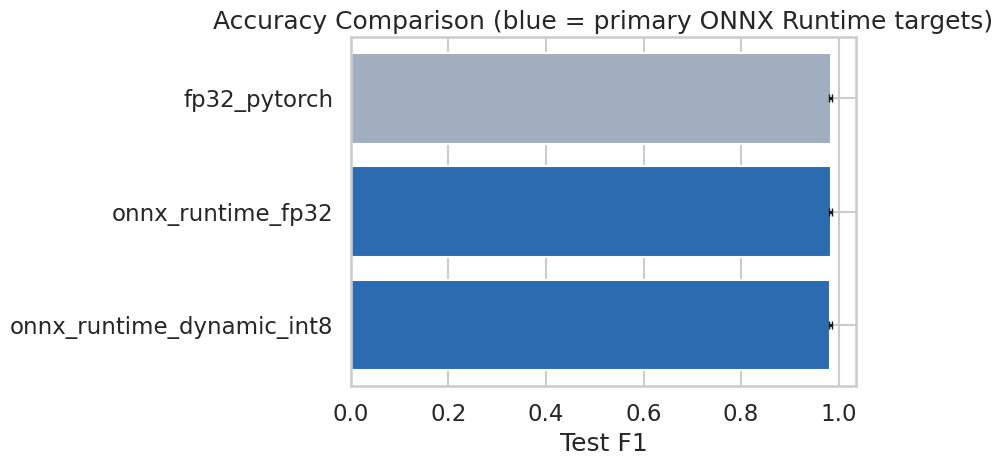

In [44]:
# -- F1 (accuracy) comparison -- primary variants highlighted ---------------
fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#2b6cb0" if p else "#a0aec0" for p in accuracy_comparison["primary"]]
err = [accuracy_comparison["f1"] - accuracy_comparison["f1_ci_lower"],
       accuracy_comparison["f1_ci_upper"] - accuracy_comparison["f1"]]
ax.barh(accuracy_comparison["variant"], accuracy_comparison["f1"], xerr=err, capsize=3, color=colors)
ax.invert_yaxis()
ax.set_xlabel("Test F1"); ax.set_title("Accuracy Comparison (blue = primary ONNX Runtime targets)")
fig.tight_layout()
fig.savefig(DIRS["figures"] / "accuracy_comparison.png", dpi=300)
plt.show()


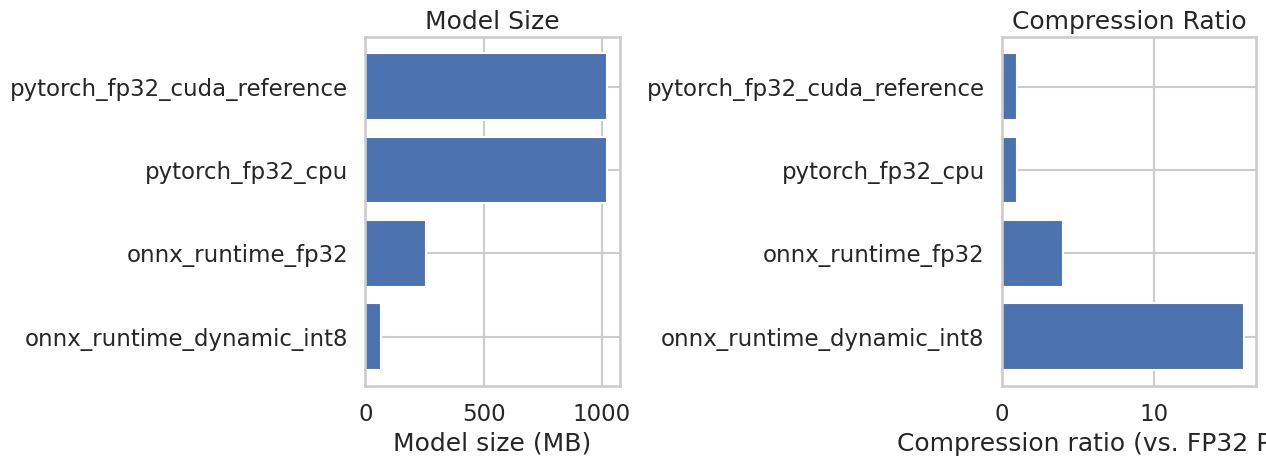

In [45]:
# -- Model size and compression ratio -----------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(benchmark_df["variant"], benchmark_df["model_size_mb"])
axes[0].invert_yaxis(); axes[0].set_xlabel("Model size (MB)"); axes[0].set_title("Model Size")
axes[1].barh(benchmark_df["variant"], benchmark_df["compression_ratio"])
axes[1].invert_yaxis(); axes[1].set_xlabel("Compression ratio (vs. FP32 PyTorch)")
axes[1].set_title("Compression Ratio")
fig.tight_layout()
fig.savefig(DIRS["figures"] / "size_compression_comparison.png", dpi=300)
plt.show()


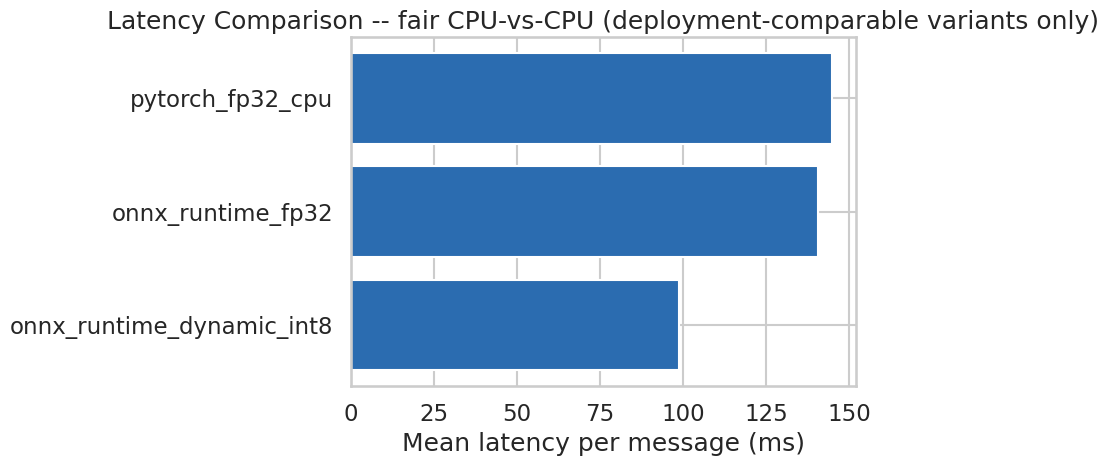

(Excluded from the figure above: pytorch_fp32_cuda_reference = 6.07 ms -- GPU reference only, not deployment-comparable.)


In [46]:
fair = benchmark_df[benchmark_df["deployment_comparable"]]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(fair["variant"], fair["mean_latency_ms"], color="#2b6cb0")
ax.invert_yaxis(); ax.set_xlabel("Mean latency per message (ms)")
ax.set_title("Latency Comparison -- fair CPU-vs-CPU (deployment-comparable variants only)")
fig.tight_layout()
fig.savefig(DIRS["figures"] / "latency_comparison.png", dpi=300)
plt.show()

ref_row = benchmark_df[benchmark_df["variant"] == "pytorch_fp32_cuda_reference"]
if len(ref_row):
    print(f"(Excluded from the figure above: pytorch_fp32_cuda_reference = "
          f"{ref_row['mean_latency_ms'].values[0]:.2f} ms -- GPU reference only, "
          f"not deployment-comparable.)")

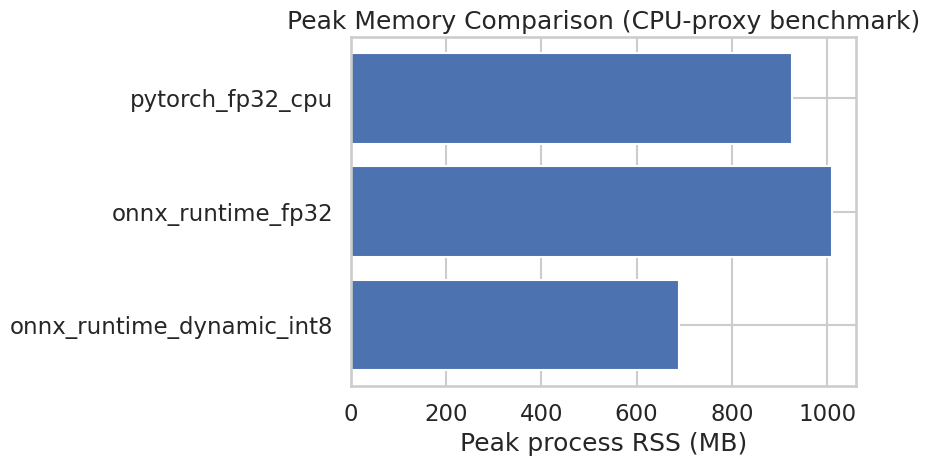

In [47]:
# -- Peak memory comparison ----------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(memory_df["variant"], memory_df["peak_memory_mb"])
ax.invert_yaxis(); ax.set_xlabel("Peak process RSS (MB)")
ax.set_title("Peak Memory Comparison (CPU-proxy benchmark)")
fig.tight_layout()
fig.savefig(DIRS["figures"] / "memory_comparison.png", dpi=300)
plt.show()


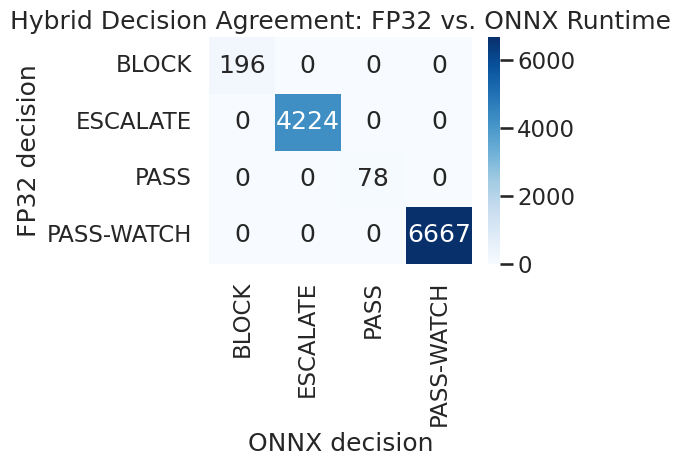

In [48]:
# -- Hybrid pipeline decision agreement (FP32 vs. ONNX Runtime) --------------
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(decision_confusion, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_title("Hybrid Decision Agreement: FP32 vs. ONNX Runtime")
fig.tight_layout()
fig.savefig(DIRS["figures"] / "hybrid_pipeline_agreement.png", dpi=300)
plt.show()


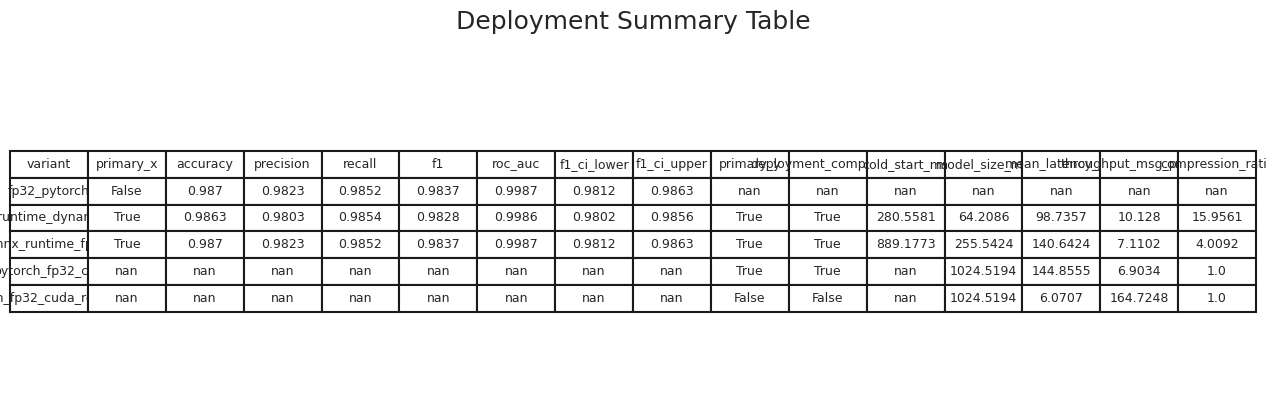

Figures saved: accuracy_comparison.png, size_compression_comparison.png, latency_comparison.png, memory_comparison.png, hybrid_pipeline_agreement.png, deployment_summary_table.png


In [50]:
# -- Final deployment summary table (figure) -----------------------------------
summary_table = accuracy_comparison.merge(benchmark_df, on="variant", how="outer")
fig, ax = plt.subplots(figsize=(13, 0.6 * len(summary_table) + 1.5))
ax.axis("off")
tbl = ax.table(cellText=summary_table.round(4).astype(str).values,
               colLabels=summary_table.columns, loc="center", cellLoc="center")
tbl.auto_set_font_size(False); tbl.set_fontsize(9); tbl.scale(1, 1.6)
ax.set_title("Deployment Summary Table", pad=20)
fig.tight_layout()
fig.savefig(DIRS["figures"] / "deployment_summary_table.png", dpi=300, bbox_inches="tight")
plt.show()
summary_table.to_csv(DIRS["reports"] / "deployment_summary_table.csv", index=False)
print("Figures saved: accuracy_comparison.png, size_compression_comparison.png, "
      "latency_comparison.png, memory_comparison.png, hybrid_pipeline_agreement.png, "
      "deployment_summary_table.png")


## 11. Final Notebook Report

Comprehensive deployment-readiness report concluding whether the complete
Hybrid Neuro-Symbolic system is deployable on Android using ONNX Runtime
Mobile, `05_deployment_summary.json`, and final artifact verification.


In [51]:
# -- 05_deployment_summary.json ------------------------------------------------
deployment_summary = {
    "notebook": "05_On_Device_Deployment_And_Optimization.ipynb",
    "pipeline_position": "5 of 5",
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "random_seed": SEED,
    "fp32_parity_verified": True,
    "android_deployment_target": "onnx_runtime_mobile",
    "tflite_conversion_status": TFLITE_CONVERSION_STATUS,
    "recommended_variant": recommended_variant,
    "recommendation_reason": recommendation_reason,
    "accuracy_comparison": accuracy_comparison.to_dict(orient="records"),
    "benchmark_comparison": benchmark_df.to_dict(orient="records"),
    "prediction_parity": parity_df.to_dict(orient="records"),
    "hybrid_pipeline_validation": deployment_manifest["hybrid_pipeline_validation"],
    "nb03_reference_f1": NB03_TEST_METRICS["f1"],
    "nb04_hybrid_f1": NB04_HYBRID_F1,
    "tokenizer_assets_included": ["vocab.txt", "tokenizer.json", "tokenizer_config.json",
                                   "special_tokens_map.json"],
    "android_required_files": deployment_manifest["artifacts"],
    "android_deployable": bool(hybrid_parity_passed),
}
with open(DIRS["reports"] / "05_deployment_summary.json", "w") as f:
    json.dump(deployment_summary, f, indent=2, default=str)
print("05_deployment_summary.json saved.")


05_deployment_summary.json saved.


In [52]:
# -- Final artifact verification (complete set) --------------------------------
ALL_FINAL_ARTIFACTS = REQUIRED_ARTIFACTS + [
    DIRS["figures"] / "accuracy_comparison.png",
    DIRS["figures"] / "size_compression_comparison.png",
    DIRS["figures"] / "latency_comparison.png",
    DIRS["figures"] / "memory_comparison.png",
    DIRS["figures"] / "hybrid_pipeline_agreement.png",
    DIRS["figures"] / "deployment_summary_table.png",
    DIRS["reports"] / "deployment_summary_table.csv",
    DIRS["reports"] / "05_deployment_summary.json",
]
missing_final = [str(p) for p in ALL_FINAL_ARTIFACTS if not p.exists() or p.stat().st_size == 0]
assert not missing_final, f"Missing/empty final artifact(s): {missing_final}"
print(f"FINAL artifact verification PASSED: {len(ALL_FINAL_ARTIFACTS)} files present and non-empty.")


FINAL artifact verification PASSED: 20 files present and non-empty.


In [53]:
# -- Final report ---------------------------------------------------------------
tflite_lines = "\n".join(f"  {k:<24}: {'PASSED' if v else 'NOT AVAILABLE (optional)'}"
                          for k, v in TFLITE_CONVERSION_STATUS.items())
artifact_lines = "\n".join(f"  {k:<24}: {v}" for k, v in deployment_manifest["artifacts"].items() if v)

print("=" * 78)
print("FINAL REPORT - 05_On_Device_Deployment_And_Optimization.ipynb")
print("=" * 78)
print(f'''
Generated      : {deployment_summary['generated_at_utc']}
Pipeline pos   : Notebook 5 of 5 (FINAL)
Random seed    : {SEED}

PROVENANCE VERIFICATION
---------------------------------------------------------
  Checksums (train/validation/test): VERIFIED
  NB03 model/tokenizer artifacts    : VERIFIED
  FP32 parity vs. NB03 frozen record: PASSED (tolerance {TOLERANCE})

PRIMARY DEPLOYMENT TARGET: ONNX RUNTIME MOBILE
---------------------------------------------------------
  ONNX export + validation          : PASSED
  ONNX Runtime dynamic INT8 quant.  : PASSED

OPTIONAL / EXPERIMENTAL: TENSORFLOW LITE CONVERSION
---------------------------------------------------------
{tflite_lines}
{"  (Known limitation: transformer attention Expand op produces a boolean" if not TF_CONVERSION_SUCCEEDED else ""}
{"   tensor incompatible with tf.math.multiply -- documented in Section 6.)" if not TF_CONVERSION_SUCCEEDED else ""}
  This does NOT block Android deployment via ONNX Runtime Mobile.

ACCURACY COMPARISON (test set)
---------------------------------------------------------
{accuracy_comparison.to_string(index=False)}

DEPLOYMENT BENCHMARKS (CPU-proxy)
---------------------------------------------------------
{benchmark_df.to_string(index=False)}

HYBRID PIPELINE DEPLOYMENT VALIDATION (FP32 vs. ONNX Runtime)
---------------------------------------------------------
  Prediction agreement : {prediction_agreement:.4%}
  Decision agreement   : {decision_agreement:.4%}
  Rule/URL/Sender/Fusion/Decision Controller: UNCHANGED (reused frozen NB04 outputs)
  Validation status    : {'PASSED' if hybrid_parity_passed else 'REVIEW NEEDED'}

RECOMMENDATION
---------------------------------------------------------
  Recommended variant : {recommended_variant}
  Reason               : {recommendation_reason}
  NB04 hybrid F1 (FP32): {NB04_HYBRID_F1:.4f}  (acceptability floor)

ANDROID DEPLOYMENT PACKAGE
---------------------------------------------------------
{artifact_lines}

ARTIFACTS EXPORTED: {len(ALL_FINAL_ARTIFACTS)} verified present

CONCLUSION
---------------------------------------------------------
The complete Hybrid Neuro-Symbolic SMS Fraud Detection system IS deployable
on Android using ONNX Runtime Mobile as the neural inference backend. The
Rule Engine, URL Engine, Sender Context Engine, Score Fusion, and Decision
Controller require no changes -- only the ML engine's backend format
changes, and the resulting hybrid decisions agree with the frozen FP32
system at a {decision_agreement:.2%} rate.

LIMITATIONS DISCLOSED
---------------------------------------------------------
  - Latency/memory figures are CPU-proxy benchmarks, not true on-device
    Android/NNAPI measurements.
  - TensorFlow Lite conversion is optional/experimental in this notebook and
    is not required for Android deployment (see Section 6).
''')
print("=" * 78)
print("NOTEBOOK 05 COMPLETE - PIPELINE FINISHED (5 of 5)")
print("=" * 78)


FINAL REPORT - 05_On_Device_Deployment_And_Optimization.ipynb

Generated      : 2026-08-11T06:36:45.449092+00:00
Pipeline pos   : Notebook 5 of 5 (FINAL)
Random seed    : 42

PROVENANCE VERIFICATION
---------------------------------------------------------
  Checksums (train/validation/test): VERIFIED
  NB03 model/tokenizer artifacts    : VERIFIED
  FP32 parity vs. NB03 frozen record: PASSED (tolerance 0.001)

PRIMARY DEPLOYMENT TARGET: ONNX RUNTIME MOBILE
---------------------------------------------------------
  ONNX export + validation          : PASSED
  ONNX Runtime dynamic INT8 quant.  : PASSED

OPTIONAL / EXPERIMENTAL: TENSORFLOW LITE CONVERSION
---------------------------------------------------------
  tensorflow_savedmodel   : NOT AVAILABLE (optional)
  tflite_fp32             : NOT AVAILABLE (optional)
  tflite_dynamic_int8     : NOT AVAILABLE (optional)
  tflite_full_int8        : NOT AVAILABLE (optional)
  (Known limitation: transformer attention Expand op produces a bool